# TP3 — Deux cas personnels : small data et big data
## Small : mortalité des attaques de requins (pandas, scikit-learn et PySpark)

**Fadwa Haddad · Identifiant : 05** · Dépôt : `TP3_ID05/Small`

### Le notebook est-il correct ?
**Oui.** Il s'exécute de bout en bout depuis un noyau neuf (*Restart Kernel and Run All Cells*), **sans erreur**, en environ **6 minutes**, dont environ 1 min 40 pour la partie pandas / scikit-learn et le reste pour la partie PySpark (section 10). Les seuls messages en rouge sont des informations de démarrage de Spark, expliquées en section 10.1.

### Problèmes rencontrés (et résolus)
- **Structure des données différente du plan** : le CSV Kaggle est une version réduite du Global Shark Attack File, sans colonne `Injury` ni numéro de cas. L'analyse des fuites a donc porté sur toutes les colonnes texte (le texte brut de l'espèce cite « remains » ou « death »).
- **Environnement** : scikit-learn, seaborn et joblib manquaient dans le venv et ont été installés.
- **PySpark** : les processus Python de Spark n'importaient pas `src.preparation` (UDF), résolu en définissant `PYTHONPATH`. Les champs du CSV contiennent des retours à la ligne, d'où `multiLine=True` et `escape='"'` à la lecture.
- Un avertissement `FutureWarning` de scikit-learn (`ls=` dans `RocCurveDisplay`) a été corrigé à la source (`curve_kwargs`) plutôt que masqué.

### Modifications apportées (après la première version)
- Ajout d'une **référence « pays seul »** (régression logistique sur le seul pays) : le modèle la dépasse nettement (PR AUC 0,458 contre 0,247 sur le test).
- Correction de la phrase sur la **licence** des données (conditions à vérifier sur Kaggle et sur le site du GSAF).
- Ajout d'une **limite** : la forêt n'extrapole pas l'année au-delà de 2023.
- **Section 10 : traitement complet avec PySpark** (lecture, prétraitement, agrégations, random forest MLlib), comparé à pandas et scikit-learn : données identiques, scores équivalents.
- **Étiquettes d'étapes** `## [Data]`, `## [EDA]`, etc. avant chaque section, et cette cellule.

### Autres informations
- **Données non incluses** : placer `global_shark_attacks.csv` (Kaggle, *Shark Attacks*) dans `data/`. Les modèles sont régénérés dans `models/`.
- Lancer Jupyter **depuis ce dossier** (chemins relatifs). Environnement : Python 3.10, scikit-learn 1.7.2, PySpark 3.5.9, Java 11.
- Le nettoyage est dans `src/preparation.py`, réutilisé à l'identique par pandas, par Spark (UDF) et pour le déploiement.

# Prédire la mortalité d'une attaque de requin — Étape 1 (pandas / scikit-learn)

## [Introduction]

## 0. Introduction

**Problème.** Prédire si une attaque de requin est **mortelle** (classification binaire) à partir des circonstances de l'attaque (lieu, activité, espèce, période, victime, type d'incident).

**Cas d'usage : la prévention.** Identifier les situations les plus à risque (activité, région, espèce, période) pour orienter la communication auprès des baigneurs et des surfeurs. Le modèle sert à **hiérarchiser des situations**, pas à décider d'un sauvetage : rater une situation dangereuse coûte plus cher qu'une fausse alerte.

**Données.** Jeu Kaggle *Shark Attacks* (gauravkumar2525, https://www.kaggle.com/datasets/gauravkumar2525/shark-attacks), dérivé du **Global Shark Attack File (GSAF)** tenu par le *Shark Research Institute* (https://www.sharkattackfile.net). Données issues du Global Shark Attack File (Shark Research Institute), citées comme source ; conditions de réutilisation à vérifier sur la page Kaggle et le site du GSAF.

**Workflow suivi.**

| Étape | Contenu |
|---|---|
| 1. Données | chargement, qualité, définition de la cible |
| 2. Cadrage | fuites de données, périmètre, période d'étude |
| 3. EDA | taux de mortalité selon les circonstances |
| 4. Prétraitement | fonctions de nettoyage testées (`src/preparation.py`) |
| 5. Transformation | découpage train/test, `Pipeline` + `ColumnTransformer` |
| 6. Modélisation | référence naïve, 4 modèles, validation croisée, réglage |
| 7. Évaluation | test unique, seuil, importance, erreurs, robustesse temporelle |
| 8. Déploiement (préparation) | modèle `joblib`, schéma d'entrée, prédiction d'exemple |
| 9. Conclusion | réponses, limites, lien avec l'étape 2 (Spark) |

In [1]:
# Imports et configuration
import json
import re
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

RACINE = Path.cwd()                       # le notebook est à la racine du projet
assert (RACINE / "data").is_dir(), "Lancer le notebook depuis la racine du projet"
sys.path.insert(0, str(RACINE))            # pour importer src.preparation

RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Python 3.10.12 | pandas 2.3.3 | scikit-learn 1.7.2


## [Data]

## 1. Données

### 1.1 Chargement et structure

In [2]:
CHEMIN_DONNEES = RACINE / "data" / "global_shark_attacks.csv"
df_brut = pd.read_csv(CHEMIN_DONNEES, low_memory=False)
print("Dimensions :", df_brut.shape)
df_brut.head()

Dimensions : (6890, 13)


,date,year,type,country,area,location,activity,name,sex,age,fatal_y_n,time,species
0,2023-05-13,2023.0,Unprovoked,AUSTRALIA,South Australia,Elliston,Surfing,Simon Baccanello,M,46,Y,10h10,White shark
1,2023-04-29,2023.0,Unprovoked,AUSTRALIA,Western Australia,"Yallingup, Busselton",Swimming,male,M,NaN,N,11h20,1m shark
2,2022-10-07,2022.0,Unprovoked,AUSTRALIA,Western Australia,Port Hedland,Spearfishing,Robbie Peck,M,38,N,11h30,Bull shark
3,2021-10-04,2021.0,Unprovoked,USA,Florida,"Fort Pierce State Park, St. Lucie County",Surfing,Truman Van Patrick,M,25.0,N,NaN,NaN
4,2021-10-03,2021.0,Unprovoked,USA,Florida,"Jensen Beach, Martin County",Swimming,male,M,NaN,N,12h00,NaN


In [3]:
# Types, valeurs manquantes (%), cardinalité, exemples de valeurs
resume = pd.DataFrame({
    "type": df_brut.dtypes.astype(str),
    "manquants_%": (df_brut.isna().mean() * 100).round(1),
    "nb_valeurs_distinctes": df_brut.nunique(),
    "exemples (5 plus fréquentes)": [
        " | ".join(map(str, df_brut[c].value_counts().index[:5])) for c in df_brut.columns
    ],
})
resume

,type,manquants_%,nb_valeurs_distinctes,exemples (5 plus fréquentes)
date,object,4.4,5558,1957-01-01 | 1942-01-01 | 1941-01-01 | 1950-01...
year,float64,1.9,255,2015.0 | 2017.0 | 2016.0 | 2011.0 | 2014.0
type,object,0.3,11,Unprovoked | Provoked | Invalid | Watercraft |...
country,object,0.7,215,USA | AUSTRALIA | SOUTH AFRICA | NEW ZEALAND |...
area,object,7.0,862,Florida | New South Wales | Queensland | Hawai...
location,object,8.2,4427,"New Smyrna Beach, Volusia County | Daytona Bea..."
activity,object,8.5,1553,Surfing | Swimming | Fishing | Spearfishing | ...
name,object,3.2,5638,male | female | boy | 2 males | boat
sex,object,8.3,6,M | F | N | . | M x 2
age,object,43.4,232,16.0 | 19.0 | 17.0 | 17 | 15


**Constats.**
- 6 890 lignes × 13 colonnes ; toutes textuelles sauf `year`.
- Colonnes très incomplètes : `time` (51,1 % de manquants), `species` (45,3 %), `age` (43,4 %).
- `age` mélange nombres (`17`, `17.0`) et texte libre ; `sex` contient des valeurs parasites (`N`, `.`, `lli`).

**Écarts avec le plan initial.** Le jeu Kaggle est une version **réduite** du GSAF :
- il n'y a **pas de colonne `Injury`** ; la recherche de fuites porte donc sur toutes les colonnes texte (section 2.1) ;
- il n'y a **ni numéro de cas, ni lien PDF, ni source, ni enquêteur** ; seuls `name` (victime) et `location` jouent le rôle d'identifiants.

In [4]:
# Doublons exacts
doublons = df_brut[df_brut.duplicated(keep=False)]
print("Lignes en double (hors première occurrence) :", df_brut.duplicated().sum())
doublons.sort_values(["year", "country"])

Lignes en double (hors première occurrence) : 3


,date,year,type,country,area,location,activity,name,sex,age,fatal_y_n,time,species
723,1885-07-26,1885.0,Sea Disaster,USA,Hawaii,Kau District,Wreck of the schooner Pohoiki,sailor,M,NaN,N,NaN,NaN
3923,1885-07-26,1885.0,Sea Disaster,USA,Hawaii,Kau District,Wreck of the schooner Pohoiki,sailor,M,NaN,N,NaN,NaN
5127,1890-01-01,1890.0,Unprovoked,INDIA,Tamil Nadu,Tuticorin,Diving,a pearl diver,M,NaN,UNKNOWN,NaN,NaN
6370,1890-01-01,1890.0,Unprovoked,INDIA,Tamil Nadu,Tuticorin,Diving,a pearl diver,M,NaN,UNKNOWN,NaN,NaN
5088,NaN,1943.0,Unprovoked,USA,Hawaii,"Midway Island, Northwestern Hawaiian Islands",Spearfishing,2 males,M,NaN,N,NaN,small sharks
5356,NaN,1943.0,Unprovoked,USA,Hawaii,"Midway Island, Northwestern Hawaiian Islands",Spearfishing,2 males,M,NaN,N,NaN,small sharks


3 lignes sont des doublons exacts du même incident (même date, lieu, victime). Elles sont supprimées au moment de définir le périmètre (section 2.3).

### 1.2 La cible : `fatal_y_n`

In [5]:
print(df_brut["fatal_y_n"].value_counts(dropna=False).to_string())

fatal_y_n
N          4804
Y          1447
UNKNOWN     631
F             3
y             1
Y x 2         1
n             1
2017.0        1
Nq            1


In [6]:
from src.preparation import nettoyer_cible

df_brut["mortelle"] = df_brut["fatal_y_n"].map(nettoyer_cible)
correspondance = (df_brut.groupby(df_brut["fatal_y_n"].astype(str), dropna=False)["mortelle"]
                  .agg(lambda s: s.iloc[0]).rename("cible").to_frame()
                  .join(df_brut["fatal_y_n"].astype(str).value_counts().rename("effectif")))
print(correspondance.sort_values("effectif", ascending=False).to_string())
n_exclues_cible = df_brut["mortelle"].isna().sum()
print(f"\nLignes exclues (cible inconnue ou ambiguë) : {n_exclues_cible} "
      f"({n_exclues_cible / len(df_brut):.1%})")

           cible  effectif
fatal_y_n                 
N            0.0      4804
Y            1.0      1447
UNKNOWN      NaN       631
F            NaN         3
2017.0       NaN         1
Nq           NaN         1
Y x 2        1.0         1
n            0.0         1
y            1.0         1

Lignes exclues (cible inconnue ou ambiguë) : 636 (9.2%)


**Règles de la cible** (`nettoyer_cible`) :
- `Y`, `y`, `Y x 2` → 1 (mortelle) ; `N`, `n` → 0 ;
- `UNKNOWN` et les valeurs ambiguës `F`, `Nq`, `2017.0` → exclues. On ne devine pas : `F` peut signifier *fatal* comme *female*, et `Nq` peut être une faute de frappe sur `N`.

**636 lignes (9,2 %) sont exclues** pour cible inconnue. Le tableau de la section 2.2 montre que 527 d'entre elles sont des incidents classés `Invalid`.

## [Data]

## 2. Cadrage et fuites de données

### 2.1 Recherche de fuites dans les colonnes textuelles

In [7]:
# Part des lignes où un mot décrivant l'issue apparaît, par colonne textuelle
MOTS_ISSUE = r"fatal|death|died|\bdead\b|killed|remains|\bbody\b(?!.?(?:board|surf))|drown"  # « body board » exclu
cols_texte = ["date", "type", "country", "area", "location", "activity", "name", "sex", "age", "time", "species"]
lignes = []
for c in cols_texte:
    m = df_brut[c].astype(str).str.contains(MOTS_ISSUE, case=False, na=False)
    lignes.append({"colonne": c, "nb_lignes": int(m.sum()), "part_%": round(100 * m.mean(), 2),
                   "taux_mortalite_si_present": round(df_brut.loc[m, "mortelle"].mean(), 3) if m.any() else np.nan,
                   "exemple": df_brut.loc[m, c].iloc[0] if m.any() else ""})
fuites = pd.DataFrame(lignes).sort_values("nb_lignes", ascending=False)
print("Taux de mortalité global (cible connue) :", round(df_brut["mortelle"].mean(), 3))
fuites

Taux de mortalité global (cible connue) : 0.232


,colonne,nb_lignes,part_%,taux_mortalite_si_present,exemple
10,species,212,3.08,0.800,"Reported by media as shark attack, but shark i..."
5,activity,26,0.38,0.286,Fishing for the shark that killed George Lundberg
6,name,4,0.06,1.000,Because of a mistaken belief that there were n...
4,location,3,0.04,0.667,"A shark was caught, its head severed from body..."
9,time,1,0.01,1.000,FATAL (Wire netting installed at local beache...
0,date,0,0.00,NaN,
1,type,0,0.00,NaN,
2,country,0,0.00,NaN,
3,area,0,0.00,NaN,
8,age,0,0.00,NaN,


**Lecture.** La colonne `Injury` étant absente, on cherche les mots qui décrivent l'issue dans toutes les colonnes texte. On constate que :
- **`species`** contient de tels mots dans **212 lignes (3,08 %)**, avec **80 % d'attaques mortelles**, contre 23,2 % en moyenne. Le texte brut de l'espèce est donc une **fuite** ;
- `activity` en contient dans 26 lignes (0,38 %). Ce sont des récits rédigés après les faits (« *Fishing for the shark that killed…* ») ;
- `time` contient une fois « FATAL (Wire netting installed…) », et `name` / `location` contiennent quelques récits.

**Décision.** Aucun texte brut n'entre dans le modèle. On n'utilise que des **catégories extraites par listes de mots-clés fermées** (section 4), qui ne contiennent aucun mot lié à l'issue. Par exemple, « FATAL… » dans `time` devient `inconnu`.

In [8]:
# Détail de la colonne species : quels mots de l'issue, et avec quel taux de mortalité ?
sp = df_brut["species"].fillna("").str.lower()
detail = []
for mot in ["remains", "death", "body", "killed", "drown", "not confirmed", "unconfirmed", "invalid", "questionable"]:
    m = sp.str.contains(mot)
    detail.append({"mot": mot, "nb_lignes": int(m.sum()),
                   "taux_mortalite": round(df_brut.loc[m, "mortelle"].mean(), 3) if m.any() else np.nan})
pd.DataFrame(detail)

,mot,nb_lignes,taux_mortalite
0,remains,11,1.000
1,death,195,0.750
2,body,1,1.000
3,killed,4,0.500
4,drown,2,1.000
5,not confirmed,228,0.263
6,unconfirmed,75,0.000
7,invalid,103,0.000
8,questionable,84,0.667


Les 195 mentions de « death » viennent presque toutes de la formule « *Shark involvement prior to death (was) not confirmed* » : le décès a été constaté, mais l'implication du requin n'est pas établie. Ces incidents relèvent surtout du type `Invalid`, exclu du périmètre en 2.2. « remains » (11 lignes, 100 % mortelles) décrit des restes retrouvés : c'est une information connue uniquement après l'issue.

In [9]:
# Une espèce identifiée l'est souvent APRÈS l'attaque (examen des plaies, des restes) :
# la simple présence d'une information sur l'espèce peut révéler la gravité.
espece_renseignee = df_brut["species"].notna()
print(df_brut.groupby(espece_renseignee.map({True: "espèce renseignée", False: "espèce absente"}))["mortelle"]
      .agg(["count", "mean"]).round(3).to_string())

                   count   mean
species                        
espèce absente      3026  0.327
espèce renseignée   3228  0.142


Sur l'ensemble du fichier, l'espèce est **moins souvent renseignée pour les attaques mortelles** : 32,7 % de mortalité quand l'espèce est absente, contre 14,2 % quand elle est renseignée. Ce résultat va à l'encontre de l'hypothèse « on identifie surtout l'espèce quand l'attaque est grave » ; il reflète surtout l'ancienneté des cas (vieux cas graves et mal documentés). La variable reste toutefois **suspecte** : elle est souvent établie après coup. Son poids est mesuré par ablation en 7.5.

### Classement des colonnes

| Colonne | Statut | Justification |
|---|---|---|
| `fatal_y_n` | **cible** | issue de l'attaque |
| `year` | utilisable | connue avant l'attaque ; capte la tendance (secours, recensement) |
| `type` | utilisable + **filtre de périmètre** | provoquée ou non : circonstance connue au moment des faits |
| `country` | utilisable | lieu ; regroupement des pays rares |
| `area` | utilisable (région) | granularité utile pour la prévention (Floride ≠ Hawaï) ; regroupement des rares |
| `activity` | utilisable **via catégories** | texte libre, 0,38 % de récits fuyants : catégories par mots-clés |
| `species` | utilisable **via catégories**, quasi-fuite surveillée | texte brut fuyant (3,08 % des lignes, 80 % mortelles) ; espèce souvent identifiée après coup |
| `sex`, `age` | utilisables | caractéristiques de la victime, connues avant |
| `time` | utilisable **via moment de la journée** | une ligne fuyante, neutralisée par le nettoyage |
| `date` | **exclue** (redondante) | l'année suffit ; nombreuses dates approximatives (`AAAA-01-01`) ; le mois dépend de l'hémisphère |
| `location` | **exclue** (quasi-identifiant) | 4 427 modalités pour 6 890 lignes : pas généralisable |
| `name` | **exclue** (identifiant) | nom de la victime (donnée personnelle), parfois un récit |

### 2.2 Périmètre : le type d'incident

In [10]:
ct = pd.crosstab(df_brut["type"].fillna("(vide)"), df_brut["fatal_y_n"].map(nettoyer_cible).map({0: "non mortelle", 1: "mortelle"}).fillna("inconnue"),
                 margins=True)
ct["taux_mortalite"] = (ct["mortelle"] / (ct["mortelle"] + ct["non mortelle"])).round(3)
ct.sort_values("All", ascending=False)

fatal_y_n,inconnue,mortelle,non mortelle,All,taux_mortalite
type,,,,,
All,636,1449,4805,6890,0.232
Unprovoked,75,1233,3757,5065,0.247
Provoked,8,20,604,632,0.032
Invalid,527,8,17,552,0.320
Watercraft,12,11,329,352,0.032
Sea Disaster,5,170,67,242,0.717
(vide),5,4,10,19,0.286
Questionable,3,3,11,17,0.214
Boat,0,0,7,7,0.000


**Périmètre retenu : `Unprovoked`, `Provoked`, `Watercraft` (et `Boat`, 7 lignes, fusionné avec `Watercraft`).** Sont exclus :
- **`Invalid`** (552 lignes) : l'implication d'un requin n'est pas établie, et la cible est inconnue pour 527 d'entre elles ;
- **`Questionable`, `Unverified`, `Unconfirmed`, `Under investigation`, `?`, type vide** (40 lignes) : incidents non confirmés ;
- **`Sea Disaster`** (242 lignes, 71,7 % mortelles) : naufrages, accidents d'avion, faits de guerre. Le décès y est souvent dû à la noyade ou à l'exposition. Ces cas sont hors du cas d'usage (baigneurs, surfeurs) et gonfleraient artificiellement le taux de mortalité.

### 2.3 Période d'étude

Lignes dans le périmètre (avant filtre de période) : 5960
Années manquantes ou aberrantes : 120


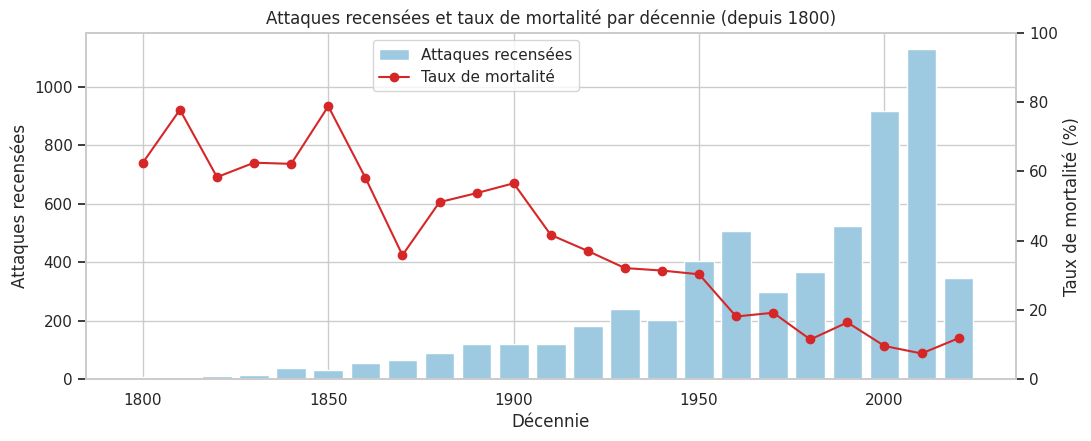

decennie  1800.0  1810.0  1820.0  1830.0  1840.0  1850.0  1860.0  1870.0  1880.0   1890.0   1900.0   1910.0  1920.0   1930.0   1940.0   1950.0   1960.0   1970.0   1980.0   1990.0   2000.0    2010.0   2020.0
effectif   8.000   9.000  12.000  16.000  37.000  33.000  55.000  67.000  90.000  121.000  122.000  120.000  181.00  240.000  204.000  406.000  508.000  297.000  366.000  524.000  917.000  1129.000  346.000
taux       0.625   0.778   0.583   0.625   0.622   0.788   0.582   0.358   0.511    0.537    0.566    0.417    0.37    0.321    0.314    0.303    0.181    0.192    0.115    0.164    0.096     0.074    0.118


In [11]:
from src.preparation import nettoyer_annee, nettoyer_type

# Périmètre retenu à ce stade : attaques confirmées, cible connue, sans doublons
df_p = df_brut.drop_duplicates().copy()
df_p["type_attaque"] = df_p["type"].map(nettoyer_type)
df_p["annee"] = df_p["year"].map(nettoyer_annee)
df_p = df_p[df_p["type_attaque"].notna() & df_p["mortelle"].notna()]
print("Lignes dans le périmètre (avant filtre de période) :", len(df_p))
print("Années manquantes ou aberrantes :", df_p["annee"].isna().sum())

df_p["decennie"] = (df_p["annee"] // 10 * 10)
par_dec = df_p[df_p["decennie"] >= 1800].groupby("decennie")["mortelle"].agg(effectif="count", taux="mean")

fig, ax1 = plt.subplots(figsize=(12, 4.5))
ax1.bar(par_dec.index, par_dec["effectif"], width=8, color="#9ecae1", label="Attaques recensées")
ax1.set_xlabel("Décennie"); ax1.set_ylabel("Attaques recensées")
ax2 = ax1.twinx()
ax2.plot(par_dec.index, par_dec["taux"] * 100, color="#d62728", marker="o", label="Taux de mortalité")
ax2.set_ylabel("Taux de mortalité (%)"); ax2.set_ylim(0, 100); ax2.grid(False)
fig.legend(loc="upper center", bbox_to_anchor=(0.45, 0.88))
ax1.set_title("Attaques recensées et taux de mortalité par décennie (depuis 1800)")
plt.show()
print(par_dec.assign(taux=lambda d: d["taux"].round(3)).T.to_string())

**Lecture du graphique.**
- Avant 1900 : moins de 125 attaques recensées par décennie, et un taux de mortalité de **36 % à 79 %**. Ne sont parvenus jusqu'à nous que les cas graves : c'est le **biais de recensement**.
- De 1900 à 1950 : le taux baisse progressivement (57 % → 30 %) à mesure que le recensement s'étoffe.
- **À partir des années 1960**, le taux passe sous 20 % (18,1 %) et reste ensuite entre 7 % et 19 %. Le volume dépasse 290 cas par décennie. Cela correspond à la mise en place d'une collecte systématique (le *Shark Attack File* est lancé à la fin des années 1950) et aux progrès des secours.

**Choix : année de début = 1960.** Avant, les cas ne sont pas comparables aux attaques actuelles, qui sont la cible du cas d'usage. Une baisse persiste au sein de la période (18 % → 7 %) : l'année est donc conservée comme variable du modèle.

In [12]:
ANNEE_DEBUT = 1960
avant = len(df_p)
df_etude_brut = df_p[df_p["annee"] >= ANNEE_DEBUT].copy()
print(f"Lignes retirées par le filtre de période (années < {ANNEE_DEBUT} ou inconnues) : "
      f"{avant - len(df_etude_brut)} sur {avant}")
print(f"Jeu d'étude : {len(df_etude_brut)} attaques, de {int(df_etude_brut['annee'].min())} à {int(df_etude_brut['annee'].max())}")
print(f"Taux de mortalité avant {ANNEE_DEBUT} : {df_p.loc[df_p['annee'] < ANNEE_DEBUT, 'mortelle'].mean():.1%} | "
      f"depuis {ANNEE_DEBUT} : {df_etude_brut['mortelle'].mean():.1%}")

Lignes retirées par le filtre de période (années < 1960 ou inconnues) : 1873 sur 5960
Jeu d'étude : 4087 attaques, de 1960 à 2023
Taux de mortalité avant 1960 : 41.1% | depuis 1960 : 12.0%


Le filtre retire **1 873 lignes** (années antérieures à 1960, plus 120 années manquantes ou aberrantes). Le jeu d'étude compte **4 087 attaques (1960-2023)**. Le contraste confirme le biais : 41,1 % de mortalité avant 1960, contre 12,0 % depuis.

In [13]:
# Bilan des exclusions successives
bilan = pd.DataFrame([
    ("Fichier brut", len(df_brut)),
    ("Après suppression des doublons exacts", len(df_brut.drop_duplicates())),
    ("Après exclusion des types hors périmètre et de la cible inconnue", avant),
    (f"Après filtre de période (>= {ANNEE_DEBUT})", len(df_etude_brut)),
], columns=["étape", "lignes"])
bilan["retirées"] = (-bilan["lignes"].diff()).fillna(0).astype(int)
bilan

,étape,lignes,retirées
0,Fichier brut,6890,0
1,Après suppression des doublons exacts,6887,3
2,Après exclusion des types hors périmètre et de...,5960,927
3,Après filtre de période (>= 1960),4087,1873


## [EDA]

## 3. Analyse exploratoire (période retenue)

Les variables nettoyées sont produites par `src/preparation.py` ; leurs règles sont détaillées et testées en section 4. On les applique ici pour pouvoir analyser des catégories lisibles plutôt que du texte libre.

In [14]:
from src.preparation import preparer_variables, tranche_age, VARIABLES_MODELE

df_etude = pd.concat([df_etude_brut[["mortelle"]].astype(int), preparer_variables(df_etude_brut)], axis=1)
df_etude["decennie"] = (df_etude["annee"] // 10 * 10).astype(int).astype(str) + "s"
df_etude["tranche_age"] = df_etude["age"].map(tranche_age)
df_etude.head()

,mortelle,annee,age,type_attaque,pays,region,activite_cat,espece_cat,sexe_cat,moment_journee,decennie,tranche_age
0,1,2023.0,46.0,non_provoquee,AUSTRALIA,SOUTH AUSTRALIA,surf,requin_blanc,M,matin,2020s,45-59
1,0,2023.0,NaN,non_provoquee,AUSTRALIA,WESTERN AUSTRALIA,baignade,inconnue,M,matin,2020s,inconnu
2,0,2022.0,38.0,non_provoquee,AUSTRALIA,WESTERN AUSTRALIA,chasse_sous_marine,requin_bouledogue,M,matin,2020s,30-44
3,0,2021.0,25.0,non_provoquee,USA,FLORIDA,surf,inconnue,M,inconnu,2020s,18-29
4,0,2021.0,NaN,non_provoquee,USA,FLORIDA,baignade,inconnue,M,apres_midi,2020s,inconnu


### 3.1 Distribution de la cible

mortelle
non mortelle    3597
mortelle         490
Part de la classe « mortelle » : 12.0%


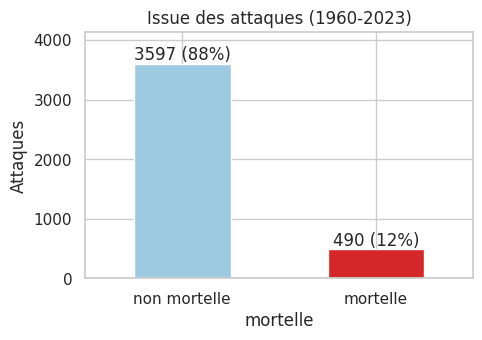

In [15]:
dist = df_etude["mortelle"].value_counts().rename(index={0: "non mortelle", 1: "mortelle"})
print(dist.to_string()); print(f"Part de la classe « mortelle » : {df_etude['mortelle'].mean():.1%}")
fig, ax = plt.subplots(figsize=(5, 3.2))
dist.plot.bar(ax=ax, color=["#9ecae1", "#d62728"], rot=0)
for i, v in enumerate(dist):
    ax.text(i, v, f"{v} ({v / dist.sum():.0%})", ha="center", va="bottom")
ax.set_title(f"Issue des attaques ({ANNEE_DEBUT}-{int(df_etude['annee'].max())})"); ax.set_ylabel("Attaques"); ax.set_ylim(0, dist.max() * 1.15)
plt.show()

**Déséquilibre marqué : 490 attaques mortelles (12,0 %) contre 3 597.** Un modèle qui prédirait toujours « non mortelle » atteindrait 88 % d'exactitude sans aucune utilité. On utilise donc la ROC AUC, la **PR AUC** et le rappel de la classe mortelle, un découpage **stratifié** et `class_weight="balanced"`.

In [16]:
TAUX_GLOBAL = df_etude["mortelle"].mean()
EFFECTIF_MIN = 30   # en dessous, l'intervalle de confiance d'un taux de ~15 % dépasse ±13 points


def taux_par(col, data=df_etude, top=None, ordre=None, titre=None):
    """Taux de mortalité par modalité (barres grisées si effectif < EFFECTIF_MIN)."""
    t = data.groupby(col)["mortelle"].agg(effectif="count", mortelles="sum", taux="mean")
    if top:
        t = t.sort_values("effectif", ascending=False).head(top)
    t = t.reindex(ordre) if ordre else t.sort_values("taux")
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(t) + 1.2))
    couleurs = ["#d62728" if n >= EFFECTIF_MIN else "#cccccc" for n in t["effectif"]]
    ax.barh(t.index.astype(str), t["taux"] * 100, color=couleurs)
    for i, (taux, n) in enumerate(zip(t["taux"], t["effectif"])):
        ax.text(taux * 100 + 0.5, i, f"{taux:.0%} (n={n})", va="center", fontsize=9)
    ax.axvline(TAUX_GLOBAL * 100, ls="--", color="black", lw=1, label=f"moyenne {TAUX_GLOBAL:.0%}")
    ax.set_xlabel("Taux de mortalité (%)"); ax.set_ylabel("")
    ax.set_xlim(0, max(t["taux"].max() * 100 * 1.3, 10))
    ax.set_title(titre or f"Taux de mortalité selon {col}"); ax.legend(loc="lower right")
    plt.show()
    return t.assign(taux=lambda d: d["taux"].round(3))

### 3.2 Taux de mortalité selon les circonstances

En gris : modalités dont l'effectif est inférieur à 30, trop faible pour conclure.

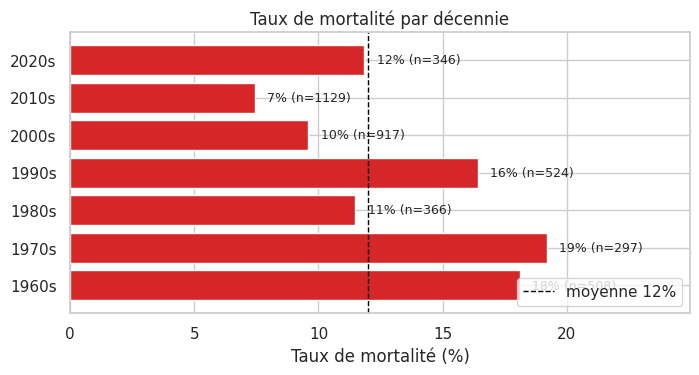

,effectif,mortelles,taux
decennie,,,
1960s,508,92,0.181
1970s,297,57,0.192
1980s,366,42,0.115
1990s,524,86,0.164
2000s,917,88,0.096
2010s,1129,84,0.074
2020s,346,41,0.118


In [17]:
taux_par("decennie", ordre=sorted(df_etude["decennie"].unique()), titre="Taux de mortalité par décennie")

La mortalité baisse de 18,1 % (années 1960) à 7,4 % (années 2010), alors que le nombre de cas recensés est multiplié par plus de deux (508 → 1 129). Une part de la baisse vient sans doute du recensement d'un plus grand nombre de morsures bénignes, ce qui dilue le taux. Les années 2020 (11,8 %) ne couvrent que 2020-2023 (n = 346).

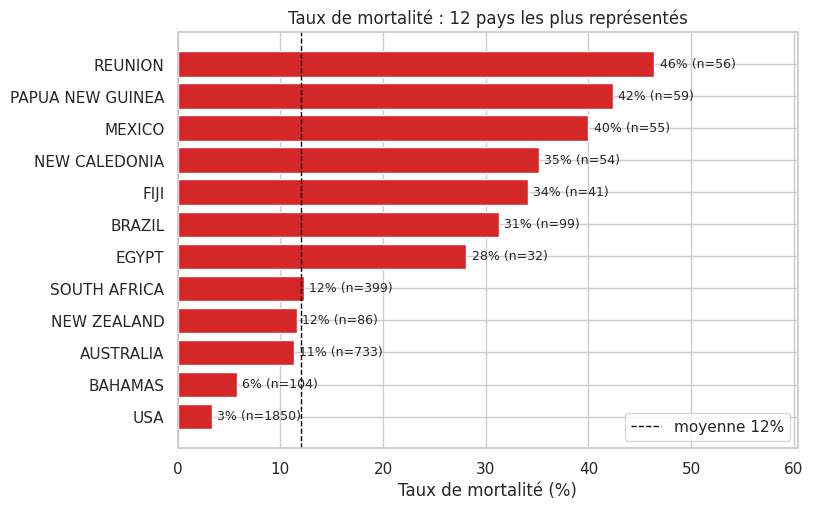

,effectif,mortelles,taux
pays,,,
USA,1850,62,0.034
BAHAMAS,104,6,0.058
AUSTRALIA,733,83,0.113
NEW ZEALAND,86,10,0.116
SOUTH AFRICA,399,49,0.123
EGYPT,32,9,0.281
BRAZIL,99,31,0.313
FIJI,41,14,0.341
NEW CALEDONIA,54,19,0.352


In [18]:
taux_par("pays", top=12, titre="Taux de mortalité : 12 pays les plus représentés")

**L'écart entre pays est le plus fort de toute l'analyse** : 3,4 % aux **USA** (n = 1 850) contre **46,4 % à La Réunion** (n = 56), 42,4 % en Papouasie-Nouvelle-Guinée et 40,0 % au Mexique. L'Australie (11,3 %) et l'Afrique du Sud (12,3 %) sont proches de la moyenne. Plusieurs explications se cumulent : accès aux secours, espèces présentes, et **exhaustivité du recensement** (les USA déclarent beaucoup de morsures légères). L'Égypte (n = 32) est à la limite de l'effectif interprétable.

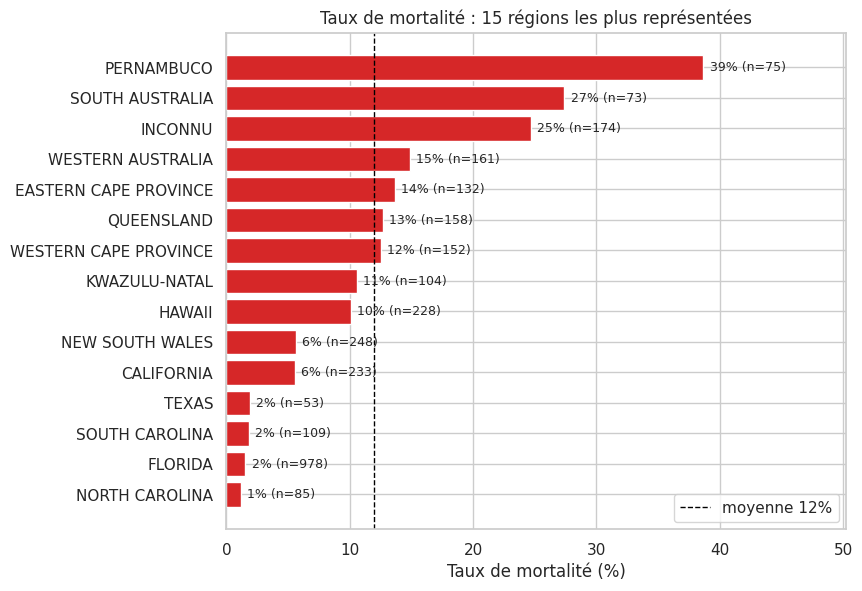

,effectif,mortelles,taux
region,,,
NORTH CAROLINA,85,1,0.012
FLORIDA,978,15,0.015
SOUTH CAROLINA,109,2,0.018
TEXAS,53,1,0.019
CALIFORNIA,233,13,0.056
NEW SOUTH WALES,248,14,0.056
HAWAII,228,23,0.101
KWAZULU-NATAL,104,11,0.106
WESTERN CAPE PROVINCE,152,19,0.125


In [19]:
taux_par("region", top=15, titre="Taux de mortalité : 15 régions les plus représentées")

Même constat à l'échelle régionale : la **Floride** (1,5 %, n = 978) et les Carolines (1-2 %) concentrent beaucoup de morsures bénignes, alors que le **Pernambouc** (Brésil, 38,7 %, n = 75) et l'**Australie-Méridionale** (27,4 %, n = 73) sont les régions fréquentes les plus mortelles. Quand la région est inconnue, la mortalité est de 24,7 % (n = 174) : un dossier peu documenté est aussi un indicateur de contexte à risque.

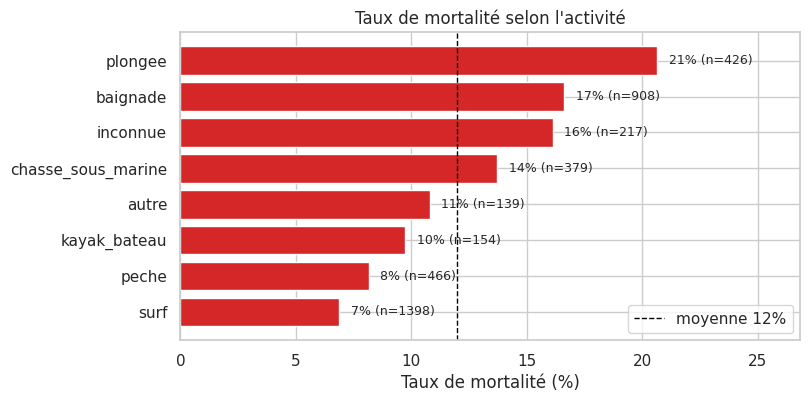

,effectif,mortelles,taux
activite_cat,,,
surf,1398,96,0.069
peche,466,38,0.082
kayak_bateau,154,15,0.097
autre,139,15,0.108
chasse_sous_marine,379,52,0.137
inconnue,217,35,0.161
baignade,908,151,0.166
plongee,426,88,0.207


In [20]:
taux_par("activite_cat", titre="Taux de mortalité selon l'activité")

La **plongée** (20,7 %, n = 426) et la **baignade** (16,6 %, n = 908) sont les activités les plus mortelles. La chasse sous-marine est proche de la moyenne (13,7 %). Le **surf**, activité la plus fréquente (n = 1 398), est la moins mortelle (6,9 %), avec la pêche (8,2 %). Attention aux effets de composition : le surf est très représenté en Floride, où presque toutes les morsures sont bénignes (voir le croisement plus bas).

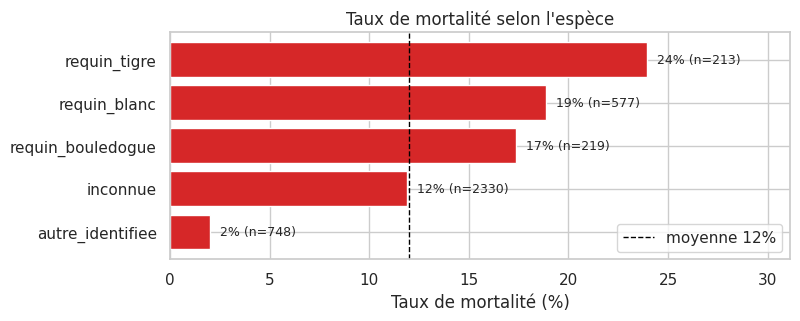

,effectif,mortelles,taux
espece_cat,,,
autre_identifiee,748,15,0.020
inconnue,2330,277,0.119
requin_bouledogue,219,38,0.174
requin_blanc,577,109,0.189
requin_tigre,213,51,0.239


In [21]:
taux_par("espece_cat", titre="Taux de mortalité selon l'espèce")

Les trois espèces connues pour les attaques graves dépassent la moyenne : **requin tigre 23,9 %** (n = 213), **requin blanc 18,9 %** (n = 577), **bouledogue 17,4 %** (n = 219). Les autres espèces identifiées ne sont mortelles que dans **2,0 %** des cas (n = 748 ; petites espèces comme le requin nourrice ou le wobbegong). L'espèce est inconnue dans 57 % des cas (11,9 % de mortalité).

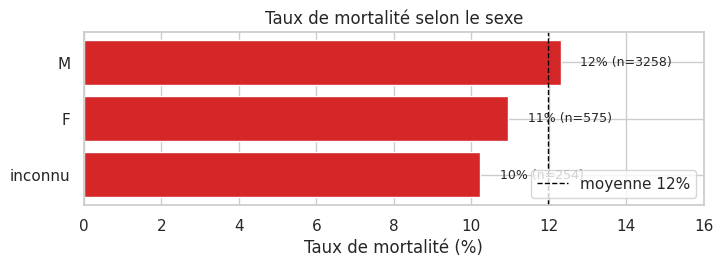

,effectif,mortelles,taux
sexe_cat,,,
inconnu,254,26,0.102
F,575,63,0.110
M,3258,401,0.123


In [22]:
taux_par("sexe_cat", titre="Taux de mortalité selon le sexe")

Écart faible entre hommes (12,3 %) et femmes (11,0 %, n = 575). L'intervalle de confiance à 95 % sur le taux féminin est d'environ ± 2,6 points : **on ne peut pas conclure** à un effet du sexe. Les hommes représentent en revanche 80 % des victimes, ce qui reflète l'exposition.

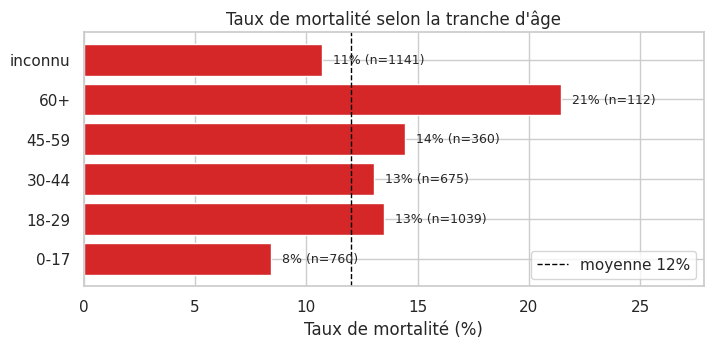

,effectif,mortelles,taux
tranche_age,,,
0-17,760,64,0.084
18-29,1039,140,0.135
30-44,675,88,0.130
45-59,360,52,0.144
60+,112,24,0.214
inconnu,1141,122,0.107


In [23]:
taux_par("tranche_age", ordre=["0-17", "18-29", "30-44", "45-59", "60+", "inconnu"], titre="Taux de mortalité selon la tranche d'âge")

La mortalité augmente avec l'âge : 8,4 % chez les 0-17 ans, 13 à 14 % de 18 à 59 ans, **21,4 % chez les 60 ans et plus**. Ce dernier effectif est modeste (n = 112, intervalle de confiance d'environ ± 7,6 points), donc la tendance est à confirmer. Quand l'âge est inconnu (28 % des cas), le taux est de 10,7 %.

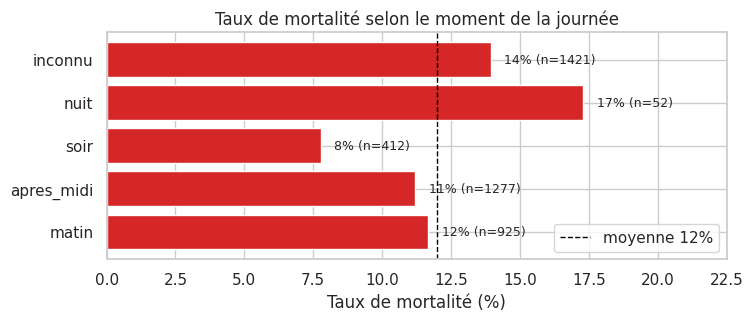

,effectif,mortelles,taux
moment_journee,,,
matin,925,108,0.117
apres_midi,1277,143,0.112
soir,412,32,0.078
nuit,52,9,0.173
inconnu,1421,198,0.139


In [24]:
taux_par("moment_journee", ordre=["matin", "apres_midi", "soir", "nuit", "inconnu"], titre="Taux de mortalité selon le moment de la journée")

Les écarts sont faibles : matin 11,7 %, après-midi 11,2 %, soir 7,8 %. La **nuit** atteint 17,3 %, mais sur seulement **52 cas** : l'effectif est trop faible pour conclure. L'heure est inconnue dans 35 % des cas (13,9 % de mortalité).

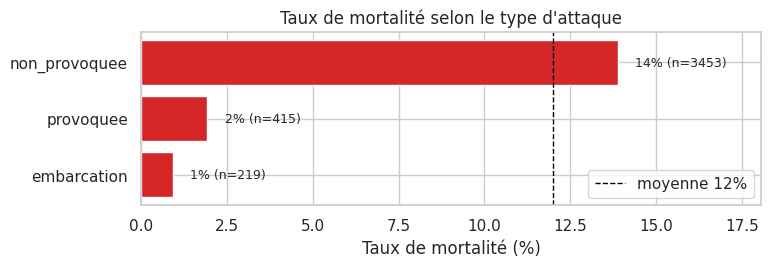

,effectif,mortelles,taux
type_attaque,,,
embarcation,219,2,0.009
provoquee,415,8,0.019
non_provoquee,3453,480,0.139


In [25]:
taux_par("type_attaque", titre="Taux de mortalité selon le type d'attaque")

Les **attaques provoquées** (1,9 %, n = 415 ; ex. pêcheur décrochant un requin) et les **attaques d'embarcations** (0,9 %, n = 219) ne sont presque jamais mortelles. Les attaques non provoquées (13,9 %) concentrent 480 des 490 décès.

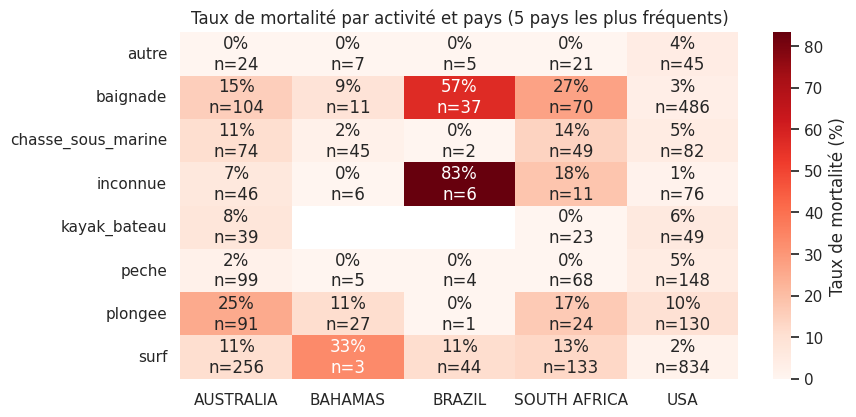

In [26]:
# Croisement pays x activité (pays les plus fréquents) : effet propre ou effet de composition ?
top_pays = df_etude["pays"].value_counts().head(5).index
croise = (df_etude[df_etude["pays"].isin(top_pays)]
          .pivot_table(index="activite_cat", columns="pays", values="mortelle", aggfunc=["mean", "count"]))
fig, ax = plt.subplots(figsize=(9, 4.5))
annot = croise["mean"].map(lambda v: f"{v:.0%}" if pd.notna(v) else "") + "\nn=" + croise["count"].fillna(0).astype(int).astype(str)
sns.heatmap(croise["mean"] * 100, annot=annot, fmt="", cmap="Reds", ax=ax, cbar_kws={"label": "Taux de mortalité (%)"})
ax.set_title("Taux de mortalité par activité et pays (5 pays les plus fréquents)"); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.show()

**Le pays domine l'activité.** La baignade est mortelle dans 57 % des cas au Brésil (n = 37), mais dans 3 % aux USA (n = 486). Aux USA, aucune activité ne dépasse 10 %. L'effet de l'activité existe tout de même à pays égal : la plongée reste plus mortelle que le surf en Australie (25 % contre 11 %) et aux USA (10 % contre 2 %). Ces **interactions** plaident pour un modèle capable de les capter (forêts, boosting). Beaucoup de cases ont moins de 30 cas : à lire avec prudence.

## [Prétraitement]

## 4. Prétraitement

Toutes les règles sont dans `src/preparation.py`, importé ici et réutilisable tel quel au déploiement. Chaque fonction est vérifiée par des assertions sur des exemples réels du fichier.

In [27]:
from src import preparation as prep

# Année : conversion numérique et bornes [1500, 2025]
assert prep.nettoyer_annee("2015.0") == 2015.0
assert np.isnan(prep.nettoyer_annee(1.0)) and np.isnan(prep.nettoyer_annee("abc"))
annees = pd.to_numeric(df_brut["year"], errors="coerce")
print("Années hors bornes dans le fichier brut :", sorted(annees[(annees < 1500) | (annees > 2025)].unique()))

# Âge
cas_age = {"17": 17, "17.0": 17, "20s": 25, "20's": 25, "mid-30s": 35, "Teen": 15, "teens": 15,
           "30 or 40": 35, "16 to 18": 17, "Ca. 33": 33, "20?": 20, "2½": 2.5, "18 months": 1.5}
for brut, attendu in cas_age.items():
    assert prep.nettoyer_age(brut) == attendu, (brut, prep.nettoyer_age(brut))
for brut in ["adult", "(adult)", "young", "28 & 26", "45 and 15", "!2", ">50", "A.M.", "X", None]:
    assert np.isnan(prep.nettoyer_age(brut)), brut

# Sexe
assert [prep.nettoyer_sexe(v) for v in ["M", " M", "M x 2", "F", "N", ".", "lli", None]] == \
       ["M", "M", "M", "F", "inconnu", "inconnu", "inconnu", "inconnu"]

# Moment de la journée
cas_heure = {"10h10": "matin", "14h30": "apres_midi", "1600": "apres_midi", "17h00 Sunset": "soir",
             "22h00": "nuit", "10j30": "matin", "11hoo": "matin", "Afternoon": "apres_midi",
             "Late afternon": "apres_midi", "Early morning": "matin", "Dusk": "soir", "Night": "nuit",
             "P.M.": "apres_midi", "--": "inconnu", None: "inconnu",
             "FATAL  (Wire netting installed at local beaches after this incident.)": "inconnu"}
for brut, attendu in cas_heure.items():
    assert prep.moment_journee(brut) == attendu, (brut, prep.moment_journee(brut))

# Espèce
cas_espece = {"White shark": "requin_blanc", "Great white shark": "requin_blanc", "Tiger shark, 3m": "requin_tigre",
              "Bull shark": "requin_bouledogue", "Zambesi shark": "requin_bouledogue",
              "Sandtiger shark": "autre_identifiee", "Grey nurse shark": "autre_identifiee",
              "Oceanic whitetip shark": "autre_identifiee", "Bull shark or tiger shark": "requin_bouledogue",
              "6' shark": "inconnue", "Invalid": "inconnue",
              "Shark involvement prior to death was not confirmed": "inconnue", None: "inconnue"}
for brut, attendu in cas_espece.items():
    assert prep.espece_principale(brut) == attendu, (brut, prep.espece_principale(brut))

# Activité
cas_activite = {"Surfing": "surf", "Body boarding": "surf", "Swimming": "baignade", "Wading": "baignade",
                "Fishing": "peche", "Kayak fishing": "peche", "Spearfishing": "chasse_sous_marine",
                "Scuba diving": "plongee", "Snorkeling": "plongee", "Kayaking": "kayak_bateau",
                "Fell overboard": "kayak_bateau", "Surf-skiing": "kayak_bateau", "Murder": "autre", None: "inconnue"}
for brut, attendu in cas_activite.items():
    assert prep.categorie_activite(brut) == attendu, (brut, prep.categorie_activite(brut))

# Lieux et cible
assert prep.normaliser_texte_lieu("  south  africa ") == "SOUTH AFRICA"
assert prep.normaliser_texte_lieu("Western  Australia") == "WESTERN AUSTRALIA"
assert prep.normaliser_texte_lieu(None) == "INCONNU"
assert [prep.nettoyer_cible(v) for v in ["Y", "y", "Y x 2", "N", " n"]] == [1, 1, 1, 0, 0]
assert all(np.isnan(prep.nettoyer_cible(v)) for v in ["UNKNOWN", "F", "Nq", "2017.0", None])
print("Toutes les assertions passent.")

Années hors bornes dans le fichier brut : [np.float64(1.0), np.float64(1000.0)]
Toutes les assertions passent.


**Toutes les assertions passent.** Deux années aberrantes (1 et 1000) deviennent manquantes ; elles sont de toute façon antérieures à la période d'étude.

**Règles retenues** (détail dans les docstrings de `src/preparation.py`) :
- **Âge** : décennie (`20s`) → milieu (25) ; `teen` → 15 ; intervalle (`30 or 40`) → moyenne ; mois → fraction d'année ; plusieurs victimes (`&`, `,`), termes vagues (`adult`, `young`) ou caractères douteux (`!2`, `>50`) → manquant ; hors [0, 100] → manquant.
- **Moment** : heure explicite d'abord (matin 5-11 h, après-midi 12-16 h, soir 17-20 h, nuit 21-4 h), puis mots-clés (`morning`, `dusk`…).
- **Espèce** : premier nom d'espèce cité. `sand tiger` et `grey nurse` sont d'autres espèces que le requin tigre ; une simple taille (« 6' shark ») donne `inconnue`.
- **Activité** : mots-clés par ordre de priorité (chasse sous-marine, puis pêche, plongée, surf, kayak/bateau, baignade). J'ai ajouté une modalité `inconnue` (activité vide), distincte de `autre` (activité renseignée mais non classée).

In [28]:
# Répartition des variables nettoyées et part des valeurs non reconnues (jeu d'étude)
NON_RECONNU = {"inconnu", "inconnue", "autre", "INCONNU"}
lignes = []
for c in ["type_attaque", "pays", "region", "activite_cat", "espece_cat", "sexe_cat", "moment_journee"]:
    vc = df_etude[c].value_counts()
    lignes.append({"variable": c, "modalites": len(vc),
                   "non_reconnu_%": round(100 * df_etude[c].isin(NON_RECONNU).mean(), 1),
                   "répartition (5 premières)": ", ".join(f"{k} {v / len(df_etude):.0%}" for k, v in vc.head(5).items())})
lignes.append({"variable": "age", "modalites": df_etude["age"].nunique(),
               "non_reconnu_%": round(100 * df_etude["age"].isna().mean(), 1),
               "répartition (5 premières)": f"médiane {df_etude['age'].median():.0f} ans, min {df_etude['age'].min():.1f}, max {df_etude['age'].max():.0f}"})
lignes.append({"variable": "annee", "modalites": df_etude["annee"].nunique(), "non_reconnu_%": 0.0,
               "répartition (5 premières)": f"{int(df_etude['annee'].min())}-{int(df_etude['annee'].max())}"})
pd.DataFrame(lignes)

,variable,modalites,non_reconnu_%,répartition (5 premières)
0,type_attaque,3,0.0,"non_provoquee 84%, provoquee 10%, embarcation 5%"
1,pays,128,0.2,"USA 45%, AUSTRALIA 18%, SOUTH AFRICA 10%, BAHA..."
2,region,470,4.3,"FLORIDA 24%, NEW SOUTH WALES 6%, CALIFORNIA 6%..."
3,activite_cat,8,8.7,"surf 34%, baignade 22%, peche 11%, plongee 10%..."
4,espece_cat,5,57.0,"inconnue 57%, autre_identifiee 18%, requin_bla..."
5,sexe_cat,3,6.2,"M 80%, F 14%, inconnu 6%"
6,moment_journee,5,34.8,"inconnu 35%, apres_midi 31%, matin 23%, soir 1..."
7,age,85,27.9,"médiane 25 ans, min 0.8, max 87"
8,annee,64,0.0,1960-2023


**Part des valeurs non reconnues** : espèce 57,0 %, moment de la journée 34,8 %, âge 27,9 %, activité 8,7 % (`autre` + `inconnue`), sexe 6,2 %, région 4,3 %, pays 0,2 %. Ces manques sont des **valeurs absentes de la source**, pas des échecs du nettoyage (voir ci-dessous). Ils sont conservés comme modalités `inconnu`, car le manque est lui-même informatif.

In [29]:
# Part des âges bruts renseignés mais non convertis (règles trop strictes ?)
age_brut = df_etude_brut["age"]
non_converti = age_brut.notna() & df_etude["age"].isna()
print(f"Âges renseignés : {age_brut.notna().sum()} | non convertis : {non_converti.sum()}")
print(age_brut[non_converti].value_counts().head(15).to_string())

Âges renseignés : 2968 | non convertis : 22
age
28 & 26        1
22, 57, 31     1
(adult)        1
30 & 32        1
28, 23 & 30    1
33 & 37        1
!2             1
!!             1
46 & 34        1
a minor        1
32 & 30        1
!6             1
Elderly        1
adult          1
36 & 26        1


Sur 2 968 âges renseignés, **seuls 22 (0,7 %) ne sont pas convertis** : ce sont exactement les cas prévus par les règles (plusieurs victimes, termes vagues, fautes de frappe).

In [30]:
# Activités classées « autre » : vérification que les règles ne ratent pas une catégorie fréquente
print(df_etude_brut.loc[df_etude["activite_cat"] == "autre", "activity"].str.lower().value_counts().head(15).to_string())

activity
feeding sharks                                  5
tagging sharks                                  4
escaping from alacatraz                         3
lifesaving drill                                3
shark watching                                  3
clamming                                        2
filming                                         2
murder                                          2
teasing a shark                                 2
finning the shark that bit him                  2
in waist-deep water                             1
sight-seeing                                    1
hand lining for shad                            1
catching sardines                               1
attempted to return injured shark to the sea    1


Le reliquat `autre` est hétérogène (nourrissage ou marquage de requins, exercices de sauvetage…) et aucune activité fréquente n'y est oubliée : la plus courante compte 5 cas.

In [31]:
# Regroupement des pays et régions rares en « AUTRE » (seuil MIN_EFFECTIF).
# Ici sur tout le jeu d'étude, pour illustration : dans le modèle, le regroupeur est
# dans le pipeline et apprend la liste des modalités fréquentes sur l'entraînement uniquement.
MIN_EFFECTIF = 20
demo = prep.RegroupeurModalitesRares(min_effectif=MIN_EFFECTIF).fit(df_etude[["pays", "region"]])
lieux = demo.transform(df_etude[["pays", "region"]])
for c in ["pays", "region"]:
    print(f"{c} : {df_etude[c].nunique()} modalités -> {lieux[c].nunique()} "
          f"(dont AUTRE = {(lieux[c] == 'AUTRE').mean():.1%} des lignes)")
print(lieux["pays"].value_counts().to_string())

pays : 128 modalités -> 17 (dont AUTRE = 10.2% des lignes)
region : 470 modalités -> 22 (dont AUTRE = 22.7% des lignes)
pays
USA                 1850
AUSTRALIA            733
AUTRE                416
SOUTH AFRICA         399
BAHAMAS              104
BRAZIL                99
NEW ZEALAND           86
PAPUA NEW GUINEA      59
REUNION               56
MEXICO                55
NEW CALEDONIA         54
FIJI                  41
MOZAMBIQUE            32
EGYPT                 32
FRENCH POLYNESIA      29
ITALY                 22
HONG KONG             20


Avec un seuil de 20 cas, les pays passent de 128 à 17 modalités (`AUTRE` = 10,2 % des lignes) et les régions de 470 à 22 (`AUTRE` = 22,7 %). En dessous de 20 cas, l'erreur type d'un taux d'environ 12 % dépasse 7 points : la modalité n'apporte que du bruit. Dans le modèle, ce regroupement est **appris dans le pipeline sur les seules données d'entraînement**.

## [Transformation]

## 5. Transformation

### 5.1 Découpage entraînement / test

In [32]:
from sklearn.model_selection import train_test_split

X = df_etude[VARIABLES_MODELE]
y = df_etude["mortelle"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Entraînement : {X_train.shape} | taux de mortalité {y_train.mean():.1%}")
print(f"Test         : {X_test.shape} | taux de mortalité {y_test.mean():.1%}")

Entraînement : (3269, 9) | taux de mortalité 12.0%
Test         : (818, 9) | taux de mortalité 12.0%


Le découpage stratifié conserve exactement la prévalence (12,0 %) dans les deux jeux : 3 269 lignes d'entraînement, 818 de test. **Le jeu de test n'est plus utilisé avant la section 7.2.**

### 5.2 Pipeline de prétraitement

In [33]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

VARS_LIEU = ["pays", "region"]
VARS_CAT = [c for c in prep.VARIABLES_CATEGORIELLES if c not in VARS_LIEU]


def construire_preprocesseur(standardiser: bool) -> ColumnTransformer:
    """Imputation + encodage ; standardisation des numériques seulement si le modèle l'exige."""
    etapes_num = [("imputation", SimpleImputer(strategy="median", add_indicator=True))]
    if standardiser:
        etapes_num.append(("standardisation", StandardScaler()))
    onehot = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    return ColumnTransformer([
        ("num", Pipeline(etapes_num), prep.VARIABLES_NUMERIQUES),
        ("lieu", Pipeline([("regroupement", prep.RegroupeurModalitesRares(min_effectif=MIN_EFFECTIF)),
                           ("onehot", onehot())]), VARS_LIEU),
        ("cat", Pipeline([("imputation", SimpleImputer(strategy="constant", fill_value="inconnu")),
                          ("onehot", onehot())]), VARS_CAT),
    ])


# Vérification : dimensions après transformation (ajusté sur l'entraînement seulement)
pre = construire_preprocesseur(standardiser=True).fit(X_train)
print("Variables après encodage :", pre.transform(X_train).shape[1])
print(list(pre.get_feature_names_out())[:12], "...")

Variables après encodage : 64
['num__annee', 'num__age', 'num__missingindicator_age', 'lieu__pays_AUSTRALIA', 'lieu__pays_AUTRE', 'lieu__pays_BAHAMAS', 'lieu__pays_BRAZIL', 'lieu__pays_EGYPT', 'lieu__pays_FIJI', 'lieu__pays_FRENCH POLYNESIA', 'lieu__pays_ITALY', 'lieu__pays_MEXICO'] ...


**Choix du pipeline.**
- **Numériques** (`annee`, `age`) : imputation par la médiane **avec indicateur de manque** (l'âge inconnu est associé à une mortalité différente : 10,7 %). Standardisation **uniquement pour la régression logistique** ; les arbres sont insensibles à l'échelle.
- **Lieux** : `RegroupeurModalitesRares` (appris sur le pli d'entraînement), puis `OneHotEncoder(handle_unknown="ignore")`.
- **Autres catégorielles** : imputation constante `inconnu` (sécurité pour le déploiement), puis one-hot.

Tout étant dans un `Pipeline`, chaque pli de validation croisée réapprend l'imputation, le regroupement et l'encodage : **aucune fuite** du pli de validation. On obtient 64 variables après encodage.

## [ML]

## 6. Modélisation

### 6.1 Référence naïve et comparaison de modèles (validation croisée sur l'entraînement)

In [34]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "rappel": "recall", "precision": "precision"}

modeles = {
    "Référence naïve (stratifiée)": (DummyClassifier(strategy="stratified", random_state=RANDOM_STATE), False),
    "Régression logistique": (LogisticRegression(class_weight="balanced", max_iter=2000), True),
    "Arbre de décision": (DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced",
                                                 random_state=RANDOM_STATE), False),
    "Random forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=-1, random_state=RANDOM_STATE), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), False),
}


def pipeline_pour(estimateur, standardiser):
    return Pipeline([("preparation", construire_preprocesseur(standardiser)), ("modele", estimateur)])


def reference_pays_seul():
    """Référence exigeante : régression logistique sur le seul pays (pays rares regroupés),
    c'est-à-dire, à peu de chose près, le taux de mortalité du pays."""
    lieu = Pipeline([("regroupement", prep.RegroupeurModalitesRares(min_effectif=MIN_EFFECTIF)),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return Pipeline([("preparation", ColumnTransformer([("lieu", lieu, ["pays"])])),
                     ("modele", LogisticRegression(class_weight="balanced", max_iter=2000))])


candidats = {nom: pipeline_pour(est, std) for nom, (est, std) in modeles.items()}
candidats["Référence pays seul"] = reference_pays_seul()

resultats = {}
for nom, pipe in candidats.items():
    cv = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
    resultats[nom] = {f"{m}": f"{cv['test_' + m].mean():.3f} ± {cv['test_' + m].std():.3f}" for m in SCORING}
    resultats[nom]["pr_auc_moy"] = cv["test_pr_auc"].mean()
comparaison = pd.DataFrame(resultats).T.sort_values("pr_auc_moy", ascending=False)
comparaison

,roc_auc,pr_auc,rappel,precision,pr_auc_moy
Random forest,0.866 ± 0.014,0.436 ± 0.026,0.725 ± 0.063,0.370 ± 0.017,0.436299
Régression logistique,0.861 ± 0.014,0.418 ± 0.014,0.809 ± 0.059,0.318 ± 0.011,0.417732
HistGradientBoosting,0.846 ± 0.015,0.403 ± 0.025,0.620 ± 0.052,0.389 ± 0.018,0.402959
Arbre de décision,0.815 ± 0.029,0.315 ± 0.021,0.837 ± 0.044,0.285 ± 0.026,0.314512
Référence pays seul,0.766 ± 0.029,0.292 ± 0.034,0.709 ± 0.103,0.230 ± 0.027,0.292099
Référence naïve (stratifiée),0.507 ± 0.028,0.124 ± 0.008,0.143 ± 0.049,0.130 ± 0.044,0.123546


**Lecture** (moyenne ± écart type sur les 5 plis) :
- la **référence naïve** donne ROC AUC 0,507 et PR AUC 0,124, soit le hasard et la prévalence ;
- la **référence « pays seul »** (régression logistique sur le seul pays, soit à peu près le taux de mortalité du pays) atteint déjà ROC AUC 0,766 et PR AUC **0,292**. C'est la référence à battre, puisque le pays domine l'EDA ;
- tous les modèles font nettement mieux. Le **random forest** est en tête en PR AUC (**0,436**) et en ROC AUC (0,866), devant la **régression logistique** (0,418 ; 0,861) et le boosting (0,403). L'**arbre seul** est nettement en retrait (0,315) ;
- l'écart entre forêt et régression logistique (0,018) est du même ordre que l'écart type entre plis (0,014 à 0,026) : les deux sont proches ;
- **la forêt dépasse nettement la référence « pays seul »** : +0,144 de PR AUC (0,436 contre 0,292, soit environ cinq écarts types) et +0,100 de ROC AUC. Les autres circonstances (espèce, activité, type, année, région) apportent donc une information réelle au-delà du seul pays.

**Métrique principale : la PR AUC.** Elle se concentre sur la classe rare qui nous intéresse ; la ROC AUC est flattée par les nombreux vrais négatifs. Le rappel et la précision affichés correspondent au seuil de 0,5, qui n'est pas celui qui sera utilisé : ils ne servent pas à comparer les modèles (le seuil est choisi en 7.1).

### 6.2 Réglage des hyperparamètres des deux meilleurs modèles

In [35]:
from sklearn.model_selection import GridSearchCV

grilles = {
    "Régression logistique": {"modele__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    "Arbre de décision": {"modele__max_depth": [3, 4, 6, 8], "modele__min_samples_leaf": [10, 20, 50]},
    "Random forest": {"modele__max_depth": [None, 8, 12], "modele__min_samples_leaf": [3, 5, 10, 20],
                      "modele__max_features": ["sqrt", 0.3]},
    "HistGradientBoosting": {"modele__learning_rate": [0.03, 0.1], "modele__max_depth": [3, 5, None],
                             "modele__min_samples_leaf": [20, 50], "modele__l2_regularization": [0.0, 1.0]},
}
a_regler = [n for n in comparaison.index if n in grilles][:2]
print("Modèles réglés :", a_regler)

recherches = {}
for nom in a_regler:
    est, std = modeles[nom]
    gs = GridSearchCV(pipeline_pour(est, std), grilles[nom], cv=CV, scoring=SCORING, refit="pr_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    recherches[nom] = gs
    i = gs.best_index_
    print(f"\n{nom} : meilleurs paramètres {gs.best_params_}")
    print(f"  PR AUC = {gs.cv_results_['mean_test_pr_auc'][i]:.3f} ± {gs.cv_results_['std_test_pr_auc'][i]:.3f}"
          f" | ROC AUC = {gs.cv_results_['mean_test_roc_auc'][i]:.3f} ± {gs.cv_results_['std_test_roc_auc'][i]:.3f}")

Modèles réglés : ['Random forest', 'Régression logistique']



Random forest : meilleurs paramètres {'modele__max_depth': None, 'modele__max_features': 'sqrt', 'modele__min_samples_leaf': 3}
  PR AUC = 0.444 ± 0.026 | ROC AUC = 0.866 ± 0.011



Régression logistique : meilleurs paramètres {'modele__C': 1}
  PR AUC = 0.418 ± 0.014 | ROC AUC = 0.861 ± 0.014


**Résultats du réglage.**
- **Random forest** : `max_depth=None`, `max_features="sqrt"`, `min_samples_leaf=3` → PR AUC **0,444 ± 0,026** (contre 0,436 avant réglage).
- **Régression logistique** : `C=1`, la valeur par défaut, reste la meilleure → PR AUC 0,418 ± 0,014.

Le gain du réglage est modeste. La grille est volontairement petite, vu la taille des données et la variance entre plis.

In [36]:
# Modèle retenu : meilleure PR AUC moyenne en validation croisée après réglage
nom_final = max(recherches, key=lambda n: recherches[n].best_score_)
modele_final = recherches[nom_final].best_estimator_
print("Modèle retenu :", nom_final, recherches[nom_final].best_params_)

Modèle retenu : Random forest {'modele__max_depth': None, 'modele__max_features': 'sqrt', 'modele__min_samples_leaf': 3}


**Modèle retenu : random forest réglé.**
- Meilleure PR AUC et meilleure ROC AUC en validation croisée.
- Il capte les **interactions pays × activité** observées dans l'EDA.
- Il est insensible à l'échelle et robuste aux modalités nombreuses.

La régression logistique reste une alternative crédible (écart d'environ un écart type), plus simple à expliquer. Ses probabilités sont aussi mieux calibrées.

## [Éval]

## 7. Évaluation finale

### 7.1 Choix du seuil de décision (sur l'entraînement, par validation croisée)

Le seuil est choisi **sans regarder le test**, à partir des probabilités hors pli de l'entraînement.

Seuil maximisant le F2 (hors pli) : 0.327 -> rappel 0.839, précision 0.312
  seuil 0.3 : rappel 0.847, précision 0.296, alertes 34.3% des cas
  seuil 0.4 : rappel 0.760, précision 0.341, alertes 26.7% des cas
  seuil 0.5 : rappel 0.658, précision 0.411, alertes 19.2% des cas
  seuil 0.6 : rappel 0.515, précision 0.459, alertes 13.5% des cas
  seuil 0.7 : rappel 0.291, précision 0.487, alertes 7.2% des cas


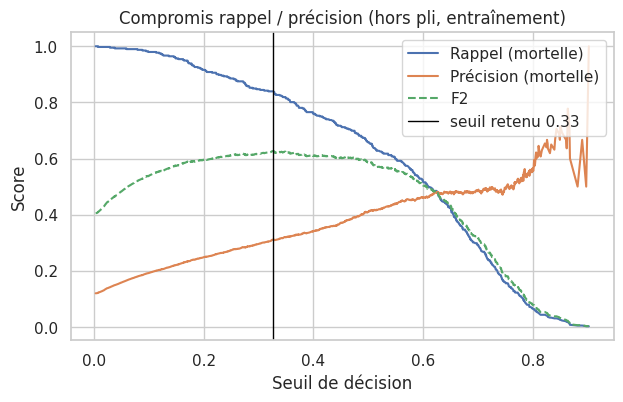

In [37]:
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import cross_val_predict

proba_oof = cross_val_predict(modele_final, X_train, y_train, cv=CV, method="predict_proba")[:, 1]
precisions, rappels, seuils = precision_recall_curve(y_train, proba_oof)
f2 = (5 * precisions * rappels) / (4 * precisions + rappels + 1e-12)
i_best = np.argmax(f2[:-1])
SEUIL = float(seuils[i_best])
print(f"Seuil maximisant le F2 (hors pli) : {SEUIL:.3f} -> rappel {rappels[i_best]:.3f}, précision {precisions[i_best]:.3f}")
for s in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba_oof >= s).astype(int)
    print(f"  seuil {s:.1f} : rappel {p[y_train == 1].mean():.3f}, précision {y_train[p == 1].mean():.3f}, "
          f"alertes {p.mean():.1%} des cas")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(seuils, rappels[:-1], label="Rappel (mortelle)"); ax.plot(seuils, precisions[:-1], label="Précision (mortelle)")
ax.plot(seuils, f2[:-1], label="F2", ls="--"); ax.axvline(SEUIL, color="black", lw=1, label=f"seuil retenu {SEUIL:.2f}")
ax.set_xlabel("Seuil de décision"); ax.set_ylabel("Score"); ax.set_title("Compromis rappel / précision (hors pli, entraînement)")
ax.legend(); plt.show()

**Choix du seuil : maximiser le F2**, qui pondère le rappel deux fois plus que la précision. En prévention, rater une situation dangereuse (faux négatif) coûte plus cher qu'une fausse alerte : celle-ci entraîne au pire un message de prudence superflu.

- Seuil retenu : **0,327**. Sur les prédictions hors pli de l'entraînement, il donne un **rappel de 0,839** pour une précision de 0,312.
- Au seuil de 0,5, le rappel tomberait à 0,658 (précision 0,411). À 0,3, on signalerait 34 % des situations comme à risque.
- Les probabilités de la forêt **ne sont pas calibrées** (`class_weight="balanced"` les gonfle) : le seuil de 0,33 ne signifie pas « 33 % de risque ». Le score sert à **classer** les situations.

### 7.2 Résultats sur le jeu de test (utilisé une seule fois)

In [38]:
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, classification_report, confusion_matrix, roc_auc_score)

modele_final.fit(X_train, y_train)
proba_test = modele_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)

naif = pipeline_pour(*modeles["Référence naïve (stratifiée)"]).fit(X_train, y_train)
proba_naif = naif.predict_proba(X_test)[:, 1]
proba_pays = reference_pays_seul().fit(X_train, y_train).predict_proba(X_test)[:, 1]

probas_test = {nom_final: proba_test, "Référence pays seul": proba_pays, "Référence naïve": proba_naif}
synthese = pd.DataFrame({
    "ROC AUC": [roc_auc_score(y_test, p) for p in probas_test.values()],
    "PR AUC": [average_precision_score(y_test, p) for p in probas_test.values()],
}, index=list(probas_test)).round(3)
print(synthese.to_string())
print(f"\nRapport de classification au seuil {SEUIL:.2f} :")
print(classification_report(y_test, pred_test, target_names=["non mortelle", "mortelle"], digits=3))
print("Au seuil par défaut 0,5 :")
print(classification_report(y_test, (proba_test >= 0.5).astype(int), target_names=["non mortelle", "mortelle"], digits=3))

                     ROC AUC  PR AUC
Random forest          0.852   0.458
Référence pays seul    0.739   0.247
Référence naïve        0.507   0.121

Rapport de classification au seuil 0.33 :
              precision    recall  f1-score   support

non mortelle      0.965     0.731     0.832       720
    mortelle      0.289     0.806     0.426        98

    accuracy                          0.740       818
   macro avg      0.627     0.768     0.629       818
weighted avg      0.884     0.740     0.783       818

Au seuil par défaut 0,5 :
              precision    recall  f1-score   support

non mortelle      0.944     0.846     0.892       720
    mortelle      0.358     0.633     0.458        98

    accuracy                          0.820       818
   macro avg      0.651     0.739     0.675       818
weighted avg      0.874     0.820     0.840       818



**Sur le test (818 attaques dont 98 mortelles) :**
- ROC AUC **0,852** et PR AUC **0,458**, contre 0,507 et 0,121 pour la référence naïve : la PR AUC est multipliée par 3,8.
- Face à la **référence « pays seul »** (ROC AUC 0,739 ; PR AUC 0,247), la PR AUC est **multipliée par 1,85**. Le modèle fait donc bien mieux que le simple taux de mortalité du pays, ce que confirme la validation croisée. Ces scores sont cohérents avec la validation croisée (0,866 ; 0,444) : pas de sur-ajustement lié à la sélection du modèle.
- Au seuil retenu : **rappel 0,806** (79 attaques mortelles sur 98 détectées, 19 manquées) et **précision 0,289** (194 fausses alertes).
- Au seuil de 0,5 : rappel 0,633, précision 0,358. Le seuil abaissé échange 7 points de précision contre 17 points de rappel, ce que le cas d'usage justifie. L'exactitude baisse (0,74 contre 0,82), mais ce n'est pas la métrique pertinente ici.

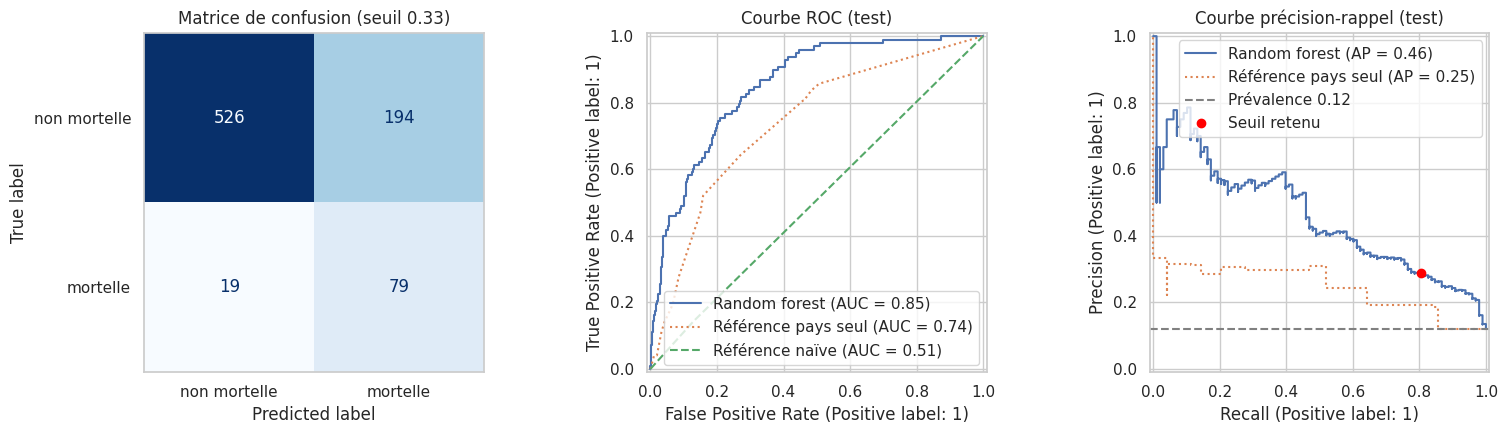

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["non mortelle", "mortelle"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title(f"Matrice de confusion (seuil {SEUIL:.2f})"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name=nom_final)
RocCurveDisplay.from_predictions(y_test, proba_pays, ax=axes[1], name="Référence pays seul", curve_kwargs={"ls": ":"})
RocCurveDisplay.from_predictions(y_test, proba_naif, ax=axes[1], name="Référence naïve", curve_kwargs={"ls": "--"})
axes[1].set_title("Courbe ROC (test)")
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2], name=nom_final)
PrecisionRecallDisplay.from_predictions(y_test, proba_pays, ax=axes[2], name="Référence pays seul", ls=":")
axes[2].axhline(y_test.mean(), ls="--", color="grey", label=f"Prévalence {y_test.mean():.2f}")
r_seuil, p_seuil = pred_test[y_test.values == 1].mean(), y_test.values[pred_test == 1].mean()
axes[2].scatter([r_seuil], [p_seuil], color="red", zorder=5, label="Seuil retenu")
axes[2].set_title("Courbe précision-rappel (test)"); axes[2].legend(loc="upper right")
plt.tight_layout(); plt.show()

Sur la courbe ROC, le modèle s'écarte nettement de la diagonale et domine la référence « pays seul » presque partout. La courbe précision-rappel reste au-dessus de la prévalence (0,12) sur toute sa longueur. Le point rouge situe le compromis retenu : environ 80 % de rappel pour environ 29 % de précision.

### 7.3 Importance des variables par permutation (test)

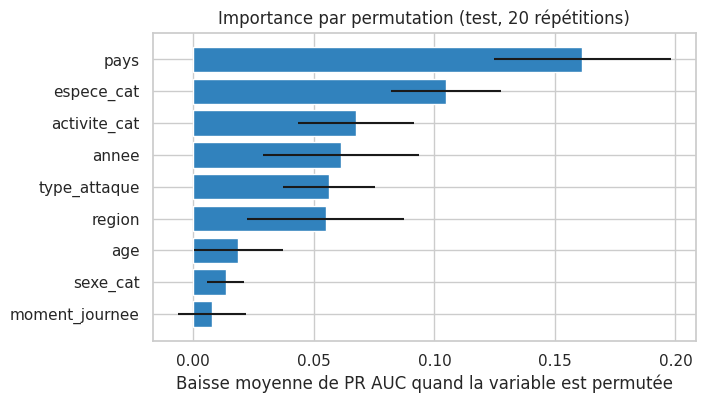

,baisse_PR_AUC,ecart_type
pays,0.1613,0.0368
espece_cat,0.1047,0.0228
activite_cat,0.0675,0.0240
annee,0.0612,0.0323
type_attaque,0.0562,0.0190
region,0.0548,0.0327
age,0.0187,0.0185
sexe_cat,0.0134,0.0077
moment_journee,0.0077,0.0142


In [40]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modele_final, X_test, y_test, scoring="average_precision",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"baisse_PR_AUC": perm.importances_mean, "ecart_type": perm.importances_std},
                   index=X_test.columns).sort_values("baisse_PR_AUC")
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp["baisse_PR_AUC"], xerr=imp["ecart_type"], color="#3182bd")
ax.set_xlabel("Baisse moyenne de PR AUC quand la variable est permutée"); ax.set_title("Importance par permutation (test, 20 répétitions)")
plt.show()
imp.sort_values("baisse_PR_AUC", ascending=False).round(4)

**Variables les plus utiles** (baisse de PR AUC quand on les permute) :
- **pays** (0,161), **espèce** (0,105), **activité** (0,068), **année** (0,061), **type d'attaque** (0,056), **région** (0,055) ;
- l'âge (0,019) et le sexe (0,013) pèsent peu. Le **moment de la journée** (0,008 ± 0,014) n'a **pas d'effet significatif**.

Le pays et la région sont corrélés : permuter l'un laisse l'autre porter une partie de l'information, donc leur importance individuelle est sous-estimée.

In [41]:
# Sens des effets : probabilité moyenne prédite par modalité (test) pour les variables les plus importantes
for c in imp.sort_values("baisse_PR_AUC", ascending=False).index[:3]:
    if c in prep.VARIABLES_CATEGORIELLES:
        t = pd.DataFrame({c: X_test[c], "proba": proba_test, "observe": y_test}).groupby(c).agg(
            effectif=("proba", "size"), proba_moyenne=("proba", "mean"), taux_observe=("observe", "mean"))
        print(t[t["effectif"] >= 10].sort_values("proba_moyenne", ascending=False).round(3).to_string(), "\n")

                  effectif  proba_moyenne  taux_observe
pays                                                   
PAPUA NEW GUINEA        17          0.656         0.412
BRAZIL                  18          0.630         0.389
REUNION                 12          0.602         0.333
NEW CALEDONIA           18          0.588         0.222
MEXICO                  10          0.570         0.300
NEW ZEALAND             19          0.340         0.158
EGYPT                   11          0.338         0.455
SOUTH AFRICA            93          0.312         0.129
AUSTRALIA              151          0.287         0.106
BAHAMAS                 19          0.271         0.105
USA                    368          0.102         0.038 

                   effectif  proba_moyenne  taux_observe
espece_cat                                              
requin_tigre             50          0.418         0.260
requin_blanc            128          0.378         0.188
requin_bouledogue        36          0.375

**Sens des effets** (score moyen sur le test, comparé au taux observé) :
- **Pays** : Papouasie-Nouvelle-Guinée, Brésil, La Réunion, Nouvelle-Calédonie et Mexique ont les scores les plus élevés ; les USA ont le plus faible (0,10, taux observé 3,8 %).
- **Espèce** : tigre > blanc ≈ bouledogue > inconnue > autre identifiée.
- **Activité** : chasse sous-marine, plongée et baignade ont des scores plus élevés que la pêche et le surf.

Le modèle retrouve donc les tendances de l'EDA. Les scores moyens sont presque toujours au-dessus des taux observés (seule l'Égypte, avec 11 cas, fait exception), ce qui confirme que les probabilités ne sont pas calibrées : seul l'**ordre** est interprétable.

### 7.4 Analyse d'erreurs

In [42]:
cols_brutes = ["year", "type", "country", "area", "activity", "sex", "age", "time", "species"]
erreurs = df_etude_brut.loc[X_test.index, cols_brutes].assign(proba=proba_test.round(3), reel=y_test.values,
                                                              predit=pred_test)
print("Faux négatifs les plus nets (mortelles jugées peu risquées) :")
display(erreurs[(erreurs.reel == 1) & (erreurs.predit == 0)].sort_values("proba").head(6))
print("Faux positifs les plus nets (non mortelles jugées très risquées) :")
display(erreurs[(erreurs.reel == 0) & (erreurs.predit == 1)].sort_values("proba", ascending=False).head(6))

Faux négatifs les plus nets (mortelles jugées peu risquées) :


,year,type,country,area,activity,sex,age,time,species,proba,reel,predit
3014,2005.0,Unprovoked,USA,Florida,Swimming with boogie board,F,14,11h15,1.8 m [6'] bull shark,0.022,1,0
2221,2021.0,Unprovoked,USA,Florida,Spearfishing,M,36.0,NaN,NaN,0.051,1,0
5515,1999.0,Unprovoked,USA,Hawaii,"Swimming, towing a kayak",F,29.0,20h30,NaN,0.122,1,0
5809,1982.0,Unprovoked,USA,Florida,Swimming,F,75.0,Prior to 10h37,NaN,0.130,1,0
5708,2015.0,Unprovoked,AUSTRALIA,New South Wales,Surfing,M,41,10h00,3.5 to 4 m shark,0.160,1,0
5780,2000.0,Unprovoked,USA,Florida,Jumped into the water,M,69.0,16h00,"Thought to involve a 2.7 m [9'], 400-lb bull s...",0.162,1,0


Faux positifs les plus nets (non mortelles jugées très risquées) :


,year,type,country,area,activity,sex,age,time,species,proba,reel,predit
369,1994.0,Unprovoked,BRAZIL,Pernambuco,Swimming,M,NaN,NaN,NaN,0.913,0,1
6545,1967.0,Unprovoked,BERMUDA,Hamilton,Floating,F,19,16h00,NaN,0.860,0,1
4528,1996.0,Unprovoked,PAPUA NEW GUINEA,Madang Province,NaN,NaN,NaN,NaN,NaN,0.831,0,1
6511,1993.0,Unprovoked,NEW CALEDONIA,South Province,Swimming,NaN,NaN,NaN,NaN,0.809,0,1
1367,1974.0,Unprovoked,HONG KONG,Mirs Bay,Freedom Swimming,M,22,NaN,NaN,0.808,0,1
1281,2010.0,Unprovoked,REUNION,Saint-Benoit,Surfing,M,34,11h00,1.5 m shark,0.796,0,1


**Exemples d'erreurs.**
- **Faux négatifs** : ce sont surtout des attaques mortelles **aux USA**. Par exemple, une adolescente de 14 ans en Floride face à un bouledogue reçoit un score de 0,022. Le modèle juge le **contexte** (Floride = morsures bénignes dans 98,5 % des cas), mais il ne voit pas ce qui fait la gravité d'une rencontre précise : taille du requin, zone mordue, délai des secours.
- **Faux positifs** : ce sont des contextes typiques des attaques mortelles (baignade au Pernambouc, Papouasie, Nouvelle-Calédonie) dont la victime a survécu. Plusieurs ont presque toutes les informations manquantes : le modèle s'appuie alors sur le seul pays.

In [43]:
# Profil des erreurs : où se concentrent les faux négatifs ?
fn = erreurs[(erreurs.reel == 1) & (erreurs.predit == 0)].index
vp = erreurs[(erreurs.reel == 1) & (erreurs.predit == 1)].index
profil = pd.DataFrame({
    "faux_négatifs": [len(fn), X_test.loc[fn, "pays"].isin(["USA"]).mean(), X_test.loc[fn, "espece_cat"].eq("inconnue").mean(),
                      X_test.loc[fn, "moment_journee"].eq("inconnu").mean(), X_test.loc[fn, "age"].isna().mean()],
    "vrais_positifs": [len(vp), X_test.loc[vp, "pays"].isin(["USA"]).mean(), X_test.loc[vp, "espece_cat"].eq("inconnue").mean(),
                       X_test.loc[vp, "moment_journee"].eq("inconnu").mean(), X_test.loc[vp, "age"].isna().mean()],
}, index=["effectif", "part USA", "part espèce inconnue", "part heure inconnue", "part âge inconnu"]).round(3)
profil

,faux_négatifs,vrais_positifs
effectif,19.000,79.000
part USA,0.579,0.038
part espèce inconnue,0.474,0.519
part heure inconnue,0.368,0.380
part âge inconnu,0.053,0.278


**58 % des faux négatifs viennent des USA, contre 3,8 % des vrais positifs.** Le modèle sous-estime structurellement le rare cas mortel en pays « sûr ». Pour la prévention, cela veut dire qu'un pays classé à faible risque ne signifie pas un risque nul.

### 7.5 Robustesse

#### a) Découpage temporel

In [44]:
from sklearn.base import clone

ANNEE_COUPURE = 2010
anc, rec = df_etude["annee"] < ANNEE_COUPURE, df_etude["annee"] >= ANNEE_COUPURE
m_temp = clone(modele_final).fit(X[anc], y[anc])
p_temp = m_temp.predict_proba(X[rec])[:, 1]
robustesse = pd.DataFrame({
    "entraînement": [f"aléatoire 80 % ({len(X_train)})", f"{ANNEE_DEBUT}-{ANNEE_COUPURE - 1} ({anc.sum()})"],
    "test": [f"aléatoire 20 % ({len(X_test)})", f"{ANNEE_COUPURE}-{int(df_etude['annee'].max())} ({rec.sum()})"],
    "prévalence test": [y_test.mean(), y[rec].mean()],
    "ROC AUC": [roc_auc_score(y_test, proba_test), roc_auc_score(y[rec], p_temp)],
    "PR AUC": [average_precision_score(y_test, proba_test), average_precision_score(y[rec], p_temp)],
    "rappel au seuil": [pred_test[y_test.values == 1].mean(), (p_temp >= SEUIL)[y[rec].values == 1].mean()],
    "précision au seuil": [y_test.values[pred_test == 1].mean(), y[rec].values[p_temp >= SEUIL].mean()],
}, index=["découpage aléatoire", "découpage temporel"])
robustesse.round(3)

,entraînement,test,prévalence test,ROC AUC,PR AUC,rappel au seuil,précision au seuil
découpage aléatoire,aléatoire 80 % (3269),aléatoire 20 % (818),0.120,0.852,0.458,0.806,0.289
découpage temporel,1960-2009 (2612),2010-2023 (1475),0.085,0.839,0.317,0.792,0.249


**Découpage temporel** (entraînement 1960-2009, test 2010-2023) :
- ROC AUC **0,839**, contre 0,852 pour le découpage aléatoire : la capacité de classement est presque intacte ;
- PR AUC **0,317** contre 0,458. La comparaison est faussée par la prévalence, plus basse sur la période récente (8,5 % contre 12,0 %). Rapportée à la référence naïve, elle reste à 3,7 fois la prévalence (contre 3,8 fois) ;
- au même seuil, le rappel reste à 0,792 et la précision baisse à 0,249.

**Conclusion :** le modèle se transpose dans le temps avec une dégradation modeste. En production, il faudra **surveiller la dérive de la prévalence** et recalibrer le seuil.

#### b) Sensibilité à la variable « espèce » (quasi-fuite)

In [45]:
# L'espèce est souvent identifiée après coup : on mesure ce que le modèle perd sans elle (CV sur l'entraînement)
X_train_sans = X_train.assign(espece_cat="inconnue")
cv_avec = cross_validate(modele_final, X_train, y_train, cv=CV, scoring=SCORING)
cv_sans = cross_validate(modele_final, X_train_sans, y_train, cv=CV, scoring=SCORING)
pd.DataFrame({k: [cv_avec["test_" + k].mean(), cv_sans["test_" + k].mean()] for k in ["roc_auc", "pr_auc"]},
             index=["avec espèce", "sans espèce"]).round(3)

,roc_auc,pr_auc
avec espèce,0.866,0.444
sans espèce,0.841,0.397


Sans l'espèce, la PR AUC passe de 0,444 à **0,397** et la ROC AUC de 0,866 à 0,841. L'espèce apporte donc un gain réel mais limité, et le modèle reste très au-dessus de la référence naïve sans elle.

L'espèce est conservée, car un sauveteur ou un observateur peut souvent la signaler. Elle est cependant **optionnelle** au déploiement (`inconnue` est une modalité apprise), et les conclusions sur l'espèce doivent tenir compte du biais d'identification après coup.

### 7.6 Limites

- **Taille** : 4 087 attaques, dont 490 mortelles. Beaucoup de modalités (pays, régions, nuit, 60 ans et plus) ont des effectifs faibles, et l'écart type entre plis est de 0,026 en PR AUC.
- **Qualité du recensement** : déclaration inégale selon les pays (les USA recensent beaucoup de morsures légères) ; l'effet « pays » mêle donc risque réel et exhaustivité de la déclaration. Données manquantes massives : espèce 57 %, heure 35 %, âge 28 %.
- **Biais** : espèce identifiée après coup, incidents à plusieurs victimes réduits à une ligne, probabilités non calibrées.
- **Extrapolation de l'année** : une forêt aléatoire n'extrapole pas au-delà des valeurs vues à l'apprentissage. Pour 2024 et après, elle se comporte comme pour 2023, la dernière année des données. La baisse tendancielle de la mortalité n'est donc pas prolongée, et il faudra réentraîner le modèle sur des données récentes.
- **Corrélation, pas causalité** : un pays « à risque » peut l'être par l'accès aux soins, et non par le comportement des requins. Le modèle désigne des **situations à surveiller**, pas des causes.

## [Déploiement]

## 8. Préparation du déploiement

Le modèle déployé est **réentraîné sur tout le jeu d'étude** (entraînement + test) avec les hyperparamètres retenus : le test a déjà servi à estimer la performance, et plus de données améliore l'estimation des modalités rares. Le seuil reste celui choisi en 7.1.

In [46]:
(RACINE / "models").mkdir(exist_ok=True)
modele_deploye = clone(modele_final).fit(X, y)
CHEMIN_MODELE = RACINE / "models" / "modele_requins.joblib"
joblib.dump(modele_deploye, CHEMIN_MODELE)
print("Modèle sauvegardé :", CHEMIN_MODELE.relative_to(RACINE), f"({CHEMIN_MODELE.stat().st_size / 1024:.0f} Ko)")

Modèle sauvegardé : models/modele_requins.joblib (10741 Ko)


In [47]:
regroupeur = modele_deploye.named_steps["preparation"].named_transformers_["lieu"].named_steps["regroupement"]
schema = {
    "description": "Entrées BRUTES attendues (format du CSV GSAF). Elles passent par "
                   "src.preparation.preparer_variables puis par le pipeline sauvegardé.",
    "modele": {"fichier": "models/modele_requins.joblib", "type": nom_final,
               "hyperparametres": {k.replace("modele__", ""): v for k, v in recherches[nom_final].best_params_.items()},
               "seuil_decision": round(SEUIL, 4), "classe_positive": "attaque mortelle (1)",
               "periode_apprentissage": [int(df_etude["annee"].min()), int(df_etude["annee"].max())],
               "scikit_learn": sklearn.__version__},
    "entrees_brutes": {
        "year": {"type": "nombre", "bornes": [prep.ANNEE_MIN_VALIDE, prep.ANNEE_MAX_VALIDE]},
        "type": {"type": "texte", "valeurs_possibles": sorted(prep.TYPES_CONSERVES)},
        "country": {"type": "texte libre", "pays_reconnus": sorted(regroupeur.modalites_frequentes_["pays"]),
                    "autre_valeur": "regroupée en AUTRE"},
        "area": {"type": "texte libre", "regions_reconnues": sorted(regroupeur.modalites_frequentes_["region"]),
                 "autre_valeur": "regroupée en AUTRE"},
        "activity": {"type": "texte libre", "categories_derivees": sorted(df_etude["activite_cat"].unique())},
        "species": {"type": "texte libre (optionnel)", "categories_derivees": sorted(df_etude["espece_cat"].unique())},
        "sex": {"type": "texte", "valeurs_possibles": ["M", "F"], "autre_valeur": "inconnu"},
        "age": {"type": "nombre ou texte ('20s', 'teen'...)", "optionnel": True},
        "time": {"type": "texte ('14h30', 'Afternoon'...)", "categories_derivees": sorted(df_etude["moment_journee"].unique()),
                 "optionnel": True},
    },
    "variables_modele": prep.VARIABLES_MODELE,
}
CHEMIN_SCHEMA = RACINE / "models" / "schema_entree.json"
CHEMIN_SCHEMA.write_text(json.dumps(schema, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(schema["modele"], indent=2, ensure_ascii=False))

{
  "fichier": "models/modele_requins.joblib",
  "type": "Random forest",
  "hyperparametres": {
    "max_depth": null,
    "max_features": "sqrt",
    "min_samples_leaf": 3
  },
  "seuil_decision": 0.327,
  "classe_positive": "attaque mortelle (1)",
  "periode_apprentissage": [
    1960,
    2023
  ],
  "scikit_learn": "1.7.2"
}


Le schéma `models/schema_entree.json` liste les **entrées brutes attendues** (format du CSV), leurs valeurs ou catégories possibles, les pays et régions reconnus (les autres deviennent `AUTRE`), le seuil de décision et la version de scikit-learn. Cette version est à figer au déploiement, car un modèle `joblib` dépend de la version qui l'a produit. Le module `src/preparation.py` doit être importable au chargement : le pipeline contient `RegroupeurModalitesRares`.

In [48]:
# Prédiction d'exemple : attaques fictives saisies à la main, rechargement du modèle depuis le disque
modele_charge = joblib.load(CHEMIN_MODELE)
seuil_charge = json.loads(CHEMIN_SCHEMA.read_text(encoding="utf-8"))["modele"]["seuil_decision"]
saisies = pd.DataFrame([
    {"year": 2024, "type": "Unprovoked", "country": "Australia ", "area": "Western Australia", "activity": "Spearfishing",
     "sex": "M", "age": "30s", "time": "17h45", "species": "White shark, 4m"},
    {"year": 2024, "type": "Unprovoked", "country": "usa", "area": "Florida", "activity": "Wading",
     "sex": "F", "age": "12", "time": "Afternoon", "species": None},
])
entrees = prep.preparer_variables(saisies)
display(entrees)
p = modele_charge.predict_proba(entrees)[:, 1]
for i, pi in enumerate(p):
    print(f"Attaque fictive {i + 1} : probabilité d'issue mortelle = {pi:.2f} -> "
          f"{'SITUATION À RISQUE' if pi >= seuil_charge else 'risque faible'} (seuil {seuil_charge:.2f})")

,annee,age,type_attaque,pays,region,activite_cat,espece_cat,sexe_cat,moment_journee
0,2024.0,35.0,non_provoquee,AUSTRALIA,WESTERN AUSTRALIA,chasse_sous_marine,requin_blanc,M,soir
1,2024.0,12.0,non_provoquee,USA,FLORIDA,baignade,inconnue,F,apres_midi


Attaque fictive 1 : probabilité d'issue mortelle = 0.64 -> SITUATION À RISQUE (seuil 0.33)
Attaque fictive 2 : probabilité d'issue mortelle = 0.02 -> risque faible (seuil 0.33)


La saisie brute (« Australia » suivi d'une espace, « usa » en minuscules, « 30s », « 17h45 ») passe par **les mêmes fonctions** que l'entraînement, puis par le pipeline rechargé depuis le disque :
- **chasse sous-marine en Australie-Occidentale, au crépuscule, requin blanc** → score 0,64, au-dessus du seuil : **situation à risque** ;
- **enfant qui patauge en Floride l'après-midi, espèce inconnue** → score 0,02 : risque faible.

C'est cohérent avec l'EDA et l'importance des variables.

## [Conclusion]

## 9. Conclusion

**Réponse au problème.** On peut classer les situations d'attaque selon leur risque d'issue mortelle bien mieux que le hasard, et mieux que le seul taux de mortalité du pays. Sur le test, la ROC AUC est de 0,852 et la PR AUC de 0,458, contre 0,247 pour la référence « pays seul » et 0,121 pour la référence naïve. Au seuil choisi pour la prévention (0,33), le modèle détecte 81 % des attaques mortelles, au prix d'une précision de 29 %.

**Situations les plus à risque** (EDA et modèle concordants) :
- **lieu** : La Réunion, Papouasie-Nouvelle-Guinée, Mexique, Nouvelle-Calédonie, Fidji, Brésil (Pernambouc), Australie-Méridionale. À l'inverse, la Floride et les Carolines sont à très faible risque ;
- **espèce** : requin tigre, blanc et bouledogue ;
- **activité** : plongée, baignade et chasse sous-marine plus que surf et pêche ;
- **victime** : attaques non provoquées, et sujets âgés (tendance à confirmer).

**Recommandation de communication.** Cibler les baigneurs et les plongeurs dans les zones à forte mortalité, où les secours sont plus éloignés, plutôt que les surfeurs de Floride, nombreux mais rarement en danger de mort.

**Limites principales.** Biais de recensement entre pays et dans le temps, données manquantes, petite taille, pas d'extrapolation de l'année au-delà de 2023, corrélation et non causalité (voir 7.6).

**Perspectives et lien avec l'étape 2 (Spark).**
- Enrichir avec la taille estimée du requin, la distance aux secours, des données météo et de fréquentation des plages.
- Calibrer les probabilités (`CalibratedClassifierCV`) pour afficher un vrai niveau de risque.
- À l'échelle Big Data, le même workflow se transpose à Spark : `pyspark.ml.Pipeline` avec `StringIndexer`, `OneHotEncoder`, `VectorAssembler` et `RandomForestClassifier`, et `CrossValidator`. Les fonctions de nettoyage deviennent des UDF ou des expressions `when/regexp`, et le découpage temporel sert de validation sur des données horodatées volumineuses.

## [Data]

## 10. Complément : le même traitement avec PySpark

Le notebook ci-dessus utilise pandas et scikit-learn. Cette partie **refait les étapes clés avec PySpark**, sur les mêmes données et avec les mêmes règles, pour deux raisons :
1. **Vérifier** que Spark retrouve exactement les mêmes données d'étude, les mêmes répartitions et des performances comparables ;
2. **Mesurer** ce que coûte Spark sur un petit jeu de données (6 890 lignes), en préparation de l'étape Big.

### 10.1 Session Spark et lecture du CSV

In [49]:
import os
import time

# Mêmes précautions d'environnement que pour l'étape Big (WSL)
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
for var in ("HADOOP_CONF_DIR", "YARN_CONF_DIR"):      # sinon Spark chercherait les fichiers dans HDFS
    os.environ.pop(var, None)
# Les processus Python de Spark (qui exécutent les UDF) doivent pouvoir importer src.preparation
os.environ["PYTHONPATH"] = str(RACINE) + os.pathsep + os.environ.get("PYTHONPATH", "")

from pyspark.sql import SparkSession, functions as F, types as T

t0 = time.time()
spark = (SparkSession.builder.master("local[*]").appName("etape1_requins_spark")
         .config("spark.driver.memory", "2g")                # petit jeu de données : 2 Go suffisent
         .config("spark.sql.shuffle.partitions", "12")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
duree_demarrage = time.time() - t0
print(f"Spark {spark.version} démarré en {duree_demarrage:.1f} s | parallélisme : {spark.sparkContext.defaultParallelism}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 14:22:15 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 démarré en 8.4 s | parallélisme : 12


Démarrer la session Spark prend **8,4 s**, avant même de lire une ligne : c'est le coût fixe de la JVM. Les deux messages en rouge sont informatifs (niveau de journalisation, bibliothèques natives Hadoop absentes et remplacées par leurs équivalents Java) ; ce ne sont pas des erreurs.

In [50]:
# Lecture du CSV : certains champs contiennent des virgules et des retours à la ligne entre guillemets
t0 = time.time()
sdf_brut = spark.read.csv(str(CHEMIN_DONNEES), header=True, inferSchema=False, multiLine=True, escape='"')
# Numéro de ligne = index pandas : le fichier multiLine est lu en une seule partition, dans l'ordre
schema_id = T.StructType([T.StructField("id", T.LongType())] + list(sdf_brut.schema.fields))
sdf_brut = spark.createDataFrame(sdf_brut.rdd.zipWithIndex().map(lambda r: (r[1],) + tuple(r[0])), schema_id).cache()
n_spark = sdf_brut.count()
print(f"{n_spark} lignes, {len(sdf_brut.columns) - 1} colonnes lues en {time.time() - t0:.1f} s (pandas : {len(df_brut)} lignes)")
assert n_spark == len(df_brut)
# Contrôle de l'alignement ligne à ligne avec pandas sur deux colonnes
echantillon = sdf_brut.where(F.col("id").isin([0, 1000, 5000, 6889])).orderBy("id").select("id", "country", "fatal_y_n").toPandas()
assert echantillon["country"].tolist() == df_brut.loc[[0, 1000, 5000, 6889], "country"].tolist()
sdf_brut.printSchema()

6890 lignes, 13 colonnes lues en 13.9 s (pandas : 6890 lignes)


root
 |-- id: long (nullable = true)
 |-- date: string (nullable = true)
 |-- year: string (nullable = true)
 |-- type: string (nullable = true)
 |-- country: string (nullable = true)
 |-- area: string (nullable = true)
 |-- location: string (nullable = true)
 |-- activity: string (nullable = true)
 |-- name: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- age: string (nullable = true)
 |-- fatal_y_n: string (nullable = true)
 |-- time: string (nullable = true)
 |-- species: string (nullable = true)



Spark lit **les mêmes 6 890 lignes et 13 colonnes** que pandas, en 13,9 s.
- `multiLine=True` et `escape='"'` sont nécessaires : certains champs contiennent des virgules et des retours à la ligne entre guillemets. Sans ces options, Spark découperait mal certaines lignes.
- Le numéro de ligne ajouté (`zipWithIndex`) correspond à l'index pandas, comme le vérifie le contrôle sur quatre lignes. Il permettra de réutiliser exactement le même découpage entraînement/test.
- Toutes les colonnes sont lues en texte (`inferSchema=False`) : les conversions sont faites explicitement au prétraitement, comme avec pandas.

In [51]:
# Valeurs manquantes (NULL ou vide), en une seule passe Spark
manq = sdf_brut.agg(*[F.round(100 * F.avg((F.col(c).isNull() | (F.trim(F.col(c)) == "")).cast("int")), 1).alias(c)
                      for c in sdf_brut.columns if c != "id"]).toPandas().T[0]
pd.DataFrame({"manquants_% (Spark)": manq, "manquants_% (pandas)": (df_brut.drop(columns="mortelle").isna().mean() * 100).round(1)})

,manquants_% (Spark),manquants_% (pandas)
date,4.4,4.4
year,1.9,1.9
type,0.3,0.3
country,0.7,0.7
area,7.0,7.0
location,8.2,8.2
activity,8.5,8.5
name,3.2,3.2
sex,8.3,8.3
age,43.4,43.4


Les pourcentages de valeurs manquantes calculés par Spark, en **une seule passe**, sont **identiques** à ceux de pandas pour les 13 colonnes : 51,1 % pour l'heure, 45,3 % pour l'espèce, 43,4 % pour l'âge.

## [Prétraitement]

### 10.2 Prétraitement avec Spark

- Les règles **simples** (cible, type d'incident, année) sont réécrites en **expressions Spark natives**, exécutées dans la JVM.
- Les règles **complexes** (âge, espèce, activité, heure, lieux) appellent **les mêmes fonctions** que pandas (`src/preparation.py`) sous forme d'**UDF Python**. Une seule source de vérité pour les règles ; sur 6 890 lignes, le surcoût d'une UDF est négligeable. Sur de gros volumes, on les réécrirait en expressions natives, comme dans l'étape Big.

In [52]:
t0 = time.time()
fatal = F.upper(F.trim("fatal_y_n"))
carte_type = F.create_map(*[F.lit(x) for kv in prep.TYPES_CONSERVES.items() for x in kv])
annee_num = F.col("year").cast("double")


def udf_float(f):
    """UDF renvoyant un double, avec NULL au lieu de NaN (convention Spark pour les manquants)."""
    def g(x):
        v = f(x)
        return None if v is None or pd.isna(v) else float(v)
    return F.udf(g, T.DoubleType())


udf_texte = lambda f: F.udf(f, T.StringType())

sdf = (sdf_brut
       .dropDuplicates([c for c in sdf_brut.columns if c != "id"])
       .withColumn("mortelle", F.when(fatal.isin("Y", "Y X 2"), 1).when(fatal == "N", 0))
       .withColumn("type_attaque", carte_type[F.trim("type")])
       .withColumn("annee", F.when(annee_num.between(prep.ANNEE_MIN_VALIDE, prep.ANNEE_MAX_VALIDE), F.floor(annee_num).cast("double")))
       .where(F.col("type_attaque").isNotNull() & F.col("mortelle").isNotNull() & (F.col("annee") >= ANNEE_DEBUT))
       .withColumn("age", udf_float(prep.nettoyer_age)("age"))
       .withColumn("pays", udf_texte(prep.normaliser_texte_lieu)("country"))
       .withColumn("region", udf_texte(prep.normaliser_texte_lieu)("area"))
       .withColumn("activite_cat", udf_texte(prep.categorie_activite)("activity"))
       .withColumn("espece_cat", udf_texte(prep.espece_principale)("species"))
       .withColumn("sexe_cat", udf_texte(prep.nettoyer_sexe)("sex"))
       .withColumn("moment_journee", udf_texte(prep.moment_journee)("time"))
       .select("id", "mortelle", *prep.VARIABLES_MODELE)
       .cache())
n_etude_spark = sdf.count()
duree_pretraitement = time.time() - t0
print(f"Jeu d'étude Spark : {n_etude_spark} attaques en {duree_pretraitement:.1f} s (pandas : {len(df_etude)})")
assert n_etude_spark == len(df_etude)
assert sorted(r["id"] for r in sdf.select("id").collect()) == sorted(df_etude.index)

Jeu d'étude Spark : 4087 attaques en 18.6 s (pandas : 4087)


Spark retrouve **exactement les mêmes 4 087 attaques** que pandas (périmètre, cible connue, sans doublons, à partir de 1960), avec les mêmes numéros de ligne, en 18,6 s.

In [53]:
# Même répartition que pandas pour chaque variable nettoyée ?
ecarts = {}
for c in ["type_attaque", "pays", "region", "activite_cat", "espece_cat", "sexe_cat", "moment_journee"]:
    vc_spark = dict(sdf.groupBy(c).count().collect())
    ecarts[c] = sum(vc_spark.get(k, 0) != v for k, v in df_etude[c].value_counts().items()) + len(set(vc_spark) - set(df_etude[c]))
a = sdf.agg(F.count("age").alias("n"), F.avg("age").alias("moy"), F.sum("mortelle").alias("mortelles")).collect()[0]
print("Modalités dont l'effectif diffère entre Spark et pandas :", ecarts)
print(f"Âge renseigné : Spark {a['n']} / pandas {df_etude['age'].notna().sum()} | âge moyen : Spark {a['moy']:.3f} / pandas {df_etude['age'].mean():.3f}")
print(f"Attaques mortelles : Spark {a['mortelles']} / pandas {int(df_etude['mortelle'].sum())}")
assert all(v == 0 for v in ecarts.values()) and a["n"] == df_etude["age"].notna().sum()

Modalités dont l'effectif diffère entre Spark et pandas : {'type_attaque': 0, 'pays': 0, 'region': 0, 'activite_cat': 0, 'espece_cat': 0, 'sexe_cat': 0, 'moment_journee': 0}
Âge renseigné : Spark 2946 / pandas 2946 | âge moyen : Spark 28.601 / pandas 28.601
Attaques mortelles : Spark 490 / pandas 490


**Parité complète avec pandas.**
- Aucune modalité n'a un effectif différent, pour les 7 variables catégorielles nettoyées.
- Âges convertis : 2 946 dans les deux cas, même âge moyen (28,601 ans).
- 490 attaques mortelles dans les deux cas.

Le prétraitement Spark est donc équivalent au prétraitement pandas.

## [EDA]

### 10.3 Exploration par agrégations Spark

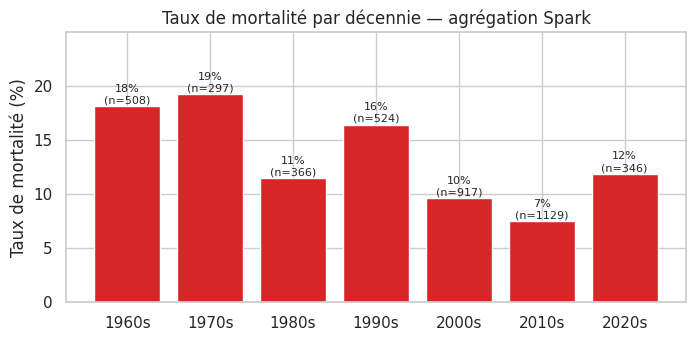

effectif  taux_spark  taux_pandas
activité          surf                    1398       0.069        0.069
                  baignade                 908       0.166        0.166
                  peche                    466       0.082        0.082
                  plongee                  426       0.207        0.207
                  chasse_sous_marine       379       0.137        0.137
                  inconnue                 217       0.161        0.161
                  kayak_bateau             154       0.097        0.097
                  autre                    139       0.108        0.108
espèce            inconnue                2330       0.119        0.119
                  autre_identifiee         748       0.020        0.020
                  requin_blanc             577       0.189        0.189
                  requin_bouledogue        219       0.174        0.174
                  requin_tigre             213       0.239        0.239
pays (6 premiers) USA                     1850       0.034        0.034
                  AUSTRALIA                733       0.113        0.113
                  SOUTH AFRICA             399       0.123        0.123
                  BAHAMAS                  104       0.058        0.058
                  BRAZIL                    99       0.313        0.313
                  NEW ZEALAND               86       0.116        0.116

In [54]:
def taux_spark(col, top=None):
    t = (sdf.groupBy(col).agg(F.count("*").alias("effectif"), F.round(F.avg("mortelle"), 3).alias("taux_spark"))
         .orderBy(F.desc("effectif")))
    t = (t.limit(top) if top else t).toPandas().set_index(col)
    t["taux_pandas"] = df_etude.groupby(col)["mortelle"].mean().round(3).reindex(t.index)
    return t


par_decennie = (sdf.withColumn("decennie", (F.floor(F.col("annee") / 10) * 10).cast("int"))
                .groupBy("decennie").agg(F.count("*").alias("effectif"), F.avg("mortelle").alias("taux")).orderBy("decennie").toPandas())
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(par_decennie["decennie"].astype(str) + "s", par_decennie["taux"] * 100, color="#d62728")
for i, (t, n) in enumerate(zip(par_decennie["taux"], par_decennie["effectif"])):
    ax.text(i, t * 100 + 0.3, f"{t:.0%}\n(n={n})", ha="center", fontsize=8)
ax.set_ylabel("Taux de mortalité (%)"); ax.set_ylim(0, par_decennie["taux"].max() * 130)
ax.set_title("Taux de mortalité par décennie — agrégation Spark")
plt.show()
pd.concat({"activité": taux_spark("activite_cat"), "espèce": taux_spark("espece_cat"), "pays (6 premiers)": taux_spark("pays", top=6)})

Les taux de mortalité calculés par **agrégation Spark** sont **identiques** à ceux de pandas, à 3 décimales près. Par exemple : plongée 20,7 %, surf 6,9 %, requin tigre 23,9 %, USA 3,4 %, Brésil 31,3 %. Le graphique par décennie reproduit la baisse observée en section 3.

## [ML]

### 10.4 Transformation et modèle avec Spark MLlib

On réutilise **exactement le même découpage entraînement / test** que scikit-learn (section 5), grâce au numéro de ligne. Les performances sont ainsi comparables sur les mêmes 818 attaques de test.

In [55]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import Imputer, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from sklearn.base import clone
from sklearn.metrics import average_precision_score, roc_auc_score

jeux = spark.createDataFrame(pd.DataFrame({"id": list(X_train.index) + list(X_test.index),
                                           "jeu": ["train"] * len(X_train) + ["test"] * len(X_test)}))
sdf_j = sdf.join(F.broadcast(jeux), "id")
s_train, s_test = sdf_j.where("jeu = 'train'").cache(), sdf_j.where("jeu = 'test'").cache()
print("Entraînement :", s_train.count(), "| test :", s_test.count())

# Regroupement des pays et régions rares, appris sur l'entraînement (même seuil que la section 4)
frequents = {c: [r[0] for r in s_train.groupBy(c).count().where(F.col("count") >= MIN_EFFECTIF).collect()]
             for c in ["pays", "region"]}


def regrouper(d):
    for c, liste in frequents.items():
        d = d.withColumn(f"{c}_g", F.when(F.col(c).isin(liste), F.col(c)).otherwise(F.lit(prep.AUTRE)))
    return d.withColumn("age_manquant", F.col("age").isNull().cast("double"))


# Poids de classes équilibrés, calculés sur l'entraînement
comptes = dict(s_train.groupBy("mortelle").count().collect())
poids = {k: s_train.count() / (2 * v) for k, v in comptes.items()}
ajoute_poids = lambda d: d.withColumn("poids", F.when(F.col("mortelle") == 1, poids[1]).otherwise(poids[0]))

CATS = ["type_attaque", "pays_g", "region_g", "activite_cat", "espece_cat", "sexe_cat", "moment_journee"]
pipeline_spark = Pipeline(stages=[
    *[StringIndexer(inputCol=c, outputCol=f"{c}_i", handleInvalid="keep") for c in CATS],
    Imputer(inputCols=["age", "annee"], outputCols=["age_imp", "annee_imp"], strategy="median"),
    VectorAssembler(inputCols=["age_imp", "annee_imp", "age_manquant"] + [f"{c}_i" for c in CATS], outputCol="features"),
    RandomForestClassifier(labelCol="mortelle", featuresCol="features", weightCol="poids", numTrees=300,
                           maxDepth=15, minInstancesPerNode=3, featureSubsetStrategy="sqrt", maxBins=64, seed=RANDOM_STATE),
])
tr = ajoute_poids(regrouper(s_train)).cache(); tr.count()
t0 = time.time(); modele_spark = pipeline_spark.fit(tr); duree_fit_spark = time.time() - t0
t0 = time.time(); clone(modele_final).fit(X_train, y_train); duree_fit_sklearn = time.time() - t0
print(f"Entraînement random forest (300 arbres) : Spark {duree_fit_spark:.1f} s | scikit-learn {duree_fit_sklearn:.1f} s")

Entraînement : 3269 | test : 818


Entraînement random forest (300 arbres) : Spark 71.7 s | scikit-learn 2.4 s


**Même découpage** que scikit-learn (3 269 attaques d'entraînement, 818 de test).
- Le pipeline MLlib (`StringIndexer`, `Imputer`, `VectorAssembler`, random forest de 300 arbres pondérée par `weightCol`) est ajusté sur l'entraînement uniquement. Le regroupement des pays et régions rares utilise le même seuil (20) et est appris sur l'entraînement.
- **Entraînement : 71,7 s avec Spark, contre 2,4 s avec scikit-learn, soit environ 30 fois plus lent.** Sur 3 269 lignes, Spark passe son temps à planifier des tâches et à sérialiser des données entre la JVM et Python, pas à calculer.

## [Éval]

### 10.5 Évaluation sur le même jeu de test

In [56]:
pred = (modele_spark.transform(regrouper(s_test))
        .select("id", "mortelle", "probability", vector_to_array("probability")[1].alias("p")).cache())
ev = BinaryClassificationEvaluator(labelCol="mortelle", rawPredictionCol="probability")
roc_spark_eval = ev.setMetricName("areaUnderROC").evaluate(pred)
pr_spark_eval = ev.setMetricName("areaUnderPR").evaluate(pred)

# Mêmes métriques que scikit-learn, calculées sur les probabilités Spark alignées sur le test pandas
p_spark = pred.select("id", "p").toPandas().set_index("id").loc[X_test.index, "p"].to_numpy()
pred_spark = (p_spark >= SEUIL).astype(int)
comparaison_outils = pd.DataFrame({
    "ROC AUC": [roc_auc_score(y_test, proba_test), roc_auc_score(y_test, p_spark)],
    "PR AUC (average precision)": [average_precision_score(y_test, proba_test), average_precision_score(y_test, p_spark)],
    f"rappel au seuil {SEUIL:.2f}": [(proba_test >= SEUIL)[y_test.values == 1].mean(), pred_spark[y_test.values == 1].mean()],
    f"précision au seuil {SEUIL:.2f}": [y_test.values[proba_test >= SEUIL].mean(), y_test.values[pred_spark == 1].mean()],
    "entraînement (s)": [duree_fit_sklearn, duree_fit_spark],
}, index=["scikit-learn (random forest)", "Spark MLlib (random forest)"]).round(3)
print(f"Évaluateur Spark : areaUnderROC = {roc_spark_eval:.3f} | areaUnderPR = {pr_spark_eval:.3f} "
      "(aire trapézoïdale, légèrement différente de l'average precision)")
print(f"Corrélation des probabilités Spark / scikit-learn sur le test : {np.corrcoef(p_spark, proba_test)[0, 1]:.3f}")
comparaison_outils

Évaluateur Spark : areaUnderROC = 0.854 | areaUnderPR = 0.447 (aire trapézoïdale, légèrement différente de l'average precision)
Corrélation des probabilités Spark / scikit-learn sur le test : 0.959


,ROC AUC,PR AUC (average precision),rappel au seuil 0.33,précision au seuil 0.33,entraînement (s)
scikit-learn (random forest),0.852,0.458,0.806,0.289,2.433
Spark MLlib (random forest),0.854,0.455,0.714,0.332,71.652


**Performances équivalentes sur le même test.**
- ROC AUC : **0,854** pour Spark, contre 0,852 pour scikit-learn.
- PR AUC (*average precision*) : **0,455**, contre 0,458.
- Les probabilités des deux forêts sont corrélées à 0,959.
- L'évaluateur natif de Spark donne une PR AUC de 0,447. Il calcule une aire par trapèzes, alors que l'*average precision* de scikit-learn est une somme en escalier ; pour comparer les deux outils, on recalcule donc les métriques de scikit-learn sur les probabilités Spark.

**Au seuil de 0,33**, le rappel est plus faible avec Spark (0,714 contre 0,806), et la précision plus élevée (0,332 contre 0,289). Ce seuil avait été choisi pour les probabilités de scikit-learn ; celles de Spark sont distribuées un peu différemment (autre implémentation des arbres, pondération par `weightCol`). En déploiement Spark, il faudrait **rechoisir le seuil** sur l'entraînement, avec la même méthode qu'en 7.1.

In [57]:
importances_spark = pd.Series(modele_spark.stages[-1].featureImportances.toArray(),
                              index=["age", "annee", "age_manquant"] + CATS).sort_values(ascending=False)
print("Importance des variables (Spark, par impureté, en %) :")
print((importances_spark / importances_spark.sum() * 100).round(1).to_string())
for d in (sdf_brut, sdf, s_train, s_test, tr, pred):
    d.unpersist()
spark.stop()
print("SparkSession arrêtée.")

Importance des variables (Spark, par impureté, en %) :
region_g          26.6
annee             14.3
pays_g            13.7
espece_cat        12.1
age               10.1
activite_cat       8.7
type_attaque       6.3
moment_journee     4.8
age_manquant       2.0
sexe_cat           1.4


SparkSession arrêtée.


Les importances par impureté de Spark placent la **région** en tête (26,6 %), devant l'année (14,3 %), le pays (13,7 %) et l'espèce (12,1 %). La géographie (région et pays : 40,3 %) domine, comme avec l'importance par permutation de la section 7.3. L'ordre diffère un peu, car l'impureté favorise les variables à nombreuses modalités et partage l'information entre deux variables corrélées (pays et région).

## [Conclusion]

### 10.6 Bilan de la partie PySpark

| | pandas / scikit-learn | PySpark |
|---|---|---|
| Données d'étude | 4 087 attaques | **4 087 attaques (identiques)** |
| Répartitions et taux | — | **identiques** |
| ROC AUC / PR AUC (test) | 0,852 / 0,458 | **0,854 / 0,455** |
| Démarrage | immédiat | 8,4 s |
| Entraînement (300 arbres) | **2,4 s** | 71,7 s |

**Conclusion.** Spark produit **les mêmes données et des résultats équivalents**, ce qui valide les deux chaînes de traitement. Mais sur 6 890 lignes, il est environ **30 fois plus lent** à entraîner et ajoute un coût de démarrage. Pour un jeu de cette taille, pandas et scikit-learn sont le bon outil. L'étape **Big** (1,88 M feux) montre qu'avec 1,3 M lignes d'entraînement, scikit-learn reste encore environ 20 fois plus rapide sur un seul portable. Spark devient indispensable quand les données ne tiennent plus en mémoire d'une machine.